In [1]:
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "widget") # To enable interactive plots in Jupyter Notebook

import json
import os
import cv2
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import re # used for extracting numbers from the json files
import ipywidgets as widgets # Used for creating interactive widgets
from ipywidgets import interact, fixed # Used for creating interactive widgets
import warnings # To solve an issue with the interactive widgets in Jupyter Notebook
import pandas as pd
from IPython.display import display, HTML

# Project Assignment - Human Pose Estimation
The aim of this work is to reconstruct the pose (joints of humans) of 10 players that are playing on a basketball court in Sanbapolis Facility and then evaluate the accuracy of the results. We have 6 camera viewpoint and different actions, each group has one action, 5 frames per action. First of all, thanks to RoboFlow we could annotate the skeletons of each players also telling which player is who, classifying them by their team and number. Now we have a dataset of 5 images per camera with the informations of where all the joints of each player are and which player is of which team.

## Camera parameters
The professor provided the calibration parameters for each camera, which we can import directly from the given `.json` files. Let's define a function to load the intrinsic parameter matrix $K$, the distortion coefficients, and construct the full camera projection matrix $P$. 

Inside the `.json` file, we explicitly find the intrinsic matrix $K$ (named `mtx`) and the distortion coefficients `dist`. However, the full camera matrix $P$ is not directly provided; instead, the file contains the extrinsic parameters represented by a rotation vector `rvec` and a translation vector `tvec`. 

These parameters are structured as follows:

*   Intrinsic Matrix (`K`): A $3 \times 3$ matrix defining the internal geometry of the camera.
    $$K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}$$
    *   **$f_x, f_y$**: The focal lengths expressed in pixel units.
    *   **$c_x, c_y$**: The principal point (optical center), representing the pixel coordinates where the optical axis intersects the image plane (usually near the center of the image).

*   Distortion Coefficients (`dist`): A $1 \times 5$ vector correcting lens imperfections.
    $$\text{dist} = \begin{bmatrix} k_1 & k_2 & p_1 & p_2 & k_3 \end{bmatrix}$$
    *   **$k_1, k_2, k_3$**: Radial distortion coefficients. They correct the "barrel" or "pincushion" effect where straight lines curve near the image edges.
    *   **$p_1, p_2$**: Tangential distortion coefficients. They correct the misalignment that occurs when the camera lens is not perfectly parallel to the imaging sensor.

*   Rotation Vector (`rvec`): A $3 \times 1$ vector using the Rodrigues axis-angle representation. The direction of the vector defines the 3D axis the camera rotates around, while its length (norm) defines the angle of rotation in radians.
    $$\text{rvec} = \begin{bmatrix} r_x & r_y & r_z \end{bmatrix}^T$$

*   Translation Vector (`tvec`): A $3 \times 1$ spatial vector. It represents the physical 3D position offset of the camera relative to the world origin, measured along the X, Y, and Z axes (scaled in millimeters).
    $$\text{tvec} = \begin{bmatrix} t_x & t_y & t_z \end{bmatrix}^T$$

#### Composing the Camera Matrix $P$

To obtain the final camera projection matrix $P \in \mathbb{R}^{3 \times 4}$, we must combine the intrinsic and extrinsic parameters. First, the rotation vector `rvec` is converted into a $3 \times 3$ rotation matrix $R$ (using the Rodrigues transformation). Then, we concatenate $R$ and `tvec` to form the $3 \times 4$ extrinsic matrix $[R|t]$. 

Finally, we compute $P$ by multiplying the intrinsic matrix $K$ with the extrinsic matrix:
$$P = K [R|t]$$


#### Cameras positions visualization  
Running the script `tests/test_cams_pos.py` we were able to reconstruc the camera position. This helped to better understand the data provided.

<img src="README_material /cams_court.png" width="80%" alt="Cams Pos">


**NOTE ABOUT THE DATA USED:** In this script, we used the calibration data contained in the folder named `camera_data_with_Rvecs_2ndversion`, as it was the one that made the most sense in terms of camera positions, etc., and also because it yields better results quality.

In [2]:
def load_cam_params(json_path):
  ''' 
  Loads camera parameters from a JSON file and computes the intrinsic matrix K, distortion coefficients dist, rotation vector rvec, translation vector tvec, and camera matrix P.

  Args:
      json_path (str): Path to the JSON file containing camera parameters.

  Returns:
      P (np.ndarray): Camera matrix.
      K (np.ndarray): Intrinsic camera parameters matrix.
      dist (np.ndarray): Distortion coefficients.
  '''
  
  # Load camera parameters from the JSON file 
  with open(json_path, 'r') as f:
    data = json.load(f)

    K = np.array(data['mtx']) # Intrinsic camera parameters matrix
    dist = np.array(data['dist']) # Distortion coefficients
    rvec = np.array(data['rvecs']) # Rotation vector (Rodrigues)
    tvec = np.array(data['tvecs']) # Translation vector

    R, _ = cv2.Rodrigues(rvec) # Convert rotation vector to rotation matrix
    Rt = np.hstack((R, tvec))  # Combine rotation matrix and translation vector into a single matrix
    P = np.dot(K, Rt) # Camera matrix = K[R|t]

    return P, K, dist

Now that we can extract the parameters of a camera with a function we can define another function that creates dictionaries of these parameters for each camera, e.g. we want a dictionary of P with all the camera matrices of the cameras.


In [3]:
def load_all_cams_params(cams_id, base_dir):
  '''
  Loads camera parameters for all cameras specified in cams_id from the base directory.

  Args:
      cams_id (list): List of camera IDs.
      base_dir (str): Base directory containing camera parameter JSON files.

  Returns:
      dict: A dictionary where keys are camera IDs and values are tuples of (P, K, dist).
  '''
  
  P_dict, K_dict, dist_dict = {}, {}, {} # Dictionaries to hold camera parameters for each camera
  
  for cam_id in cams_id:
    json_path = os.path.join(base_dir, f"cam_{cam_id}", "calib", f"camera_calib.json")
    
    if not os.path.exists(json_path):
        print(f"[WARNING] File not found for Cam {cam_id}: {json_path}")
        continue
      
    try:
      P, K, dist = load_cam_params(json_path)
      P_dict[cam_id] = P
      K_dict[cam_id] = K
      dist_dict[cam_id] = dist
    except Exception as e:
      print(f"[ERROR] Failed to load parameters for Cam {cam_id}: {e}")
  
  return P_dict, K_dict, dist_dict

Let's try these functions and print some data:

In [4]:
SCRIPT_DIR = Path.cwd()
BASE_CALIB_DIR = os.path.abspath(os.path.join(SCRIPT_DIR, "camera_data_with_Rvecs_2ndversion","Camera_config2"))


# Define available cameras in the setup
CAMS_ID = ["1", "2", "3", "4", "5", "7"]

# Set the target to analyze
# Red_11, Red_13, Red_23, Red_7, Red_9
# White_10, White_11, White_13, White_22, White_27
TARGET_PLAYER = "Red_9"   # Name of the player whose keypoints are to be extracted
TARGET_FRAME = 1   # The video frame you want to reconstruct in 3D

print(f"Target: Player {TARGET_PLAYER} | Frame: {TARGET_FRAME}")

P_dict, K_dict, dist_dict = load_all_cams_params(CAMS_ID, BASE_CALIB_DIR)

if not P_dict:
    print("[CRITICAL ERROR] No calibrations loaded. Aborting.")
    exit()

print(f"Camera matrix P of the first camera: \n{P_dict['1']}")
print(f"\n Intrinsic parameter matrix K of the first camera: \n{K_dict['1']}")
print(f"\n Distorsion coefficients dist of the first camera: \n{dist_dict['1']}")


Target: Player Red_9 | Frame: 1
Camera matrix P of the first camera: 
[[ 1.75313302e+03 -4.22564302e+03 -4.18492056e+02  4.58208837e+07]
 [ 2.66088924e+02 -1.05885180e+02 -4.33992117e+03  3.43336709e+07]
 [ 9.66644703e-01 -5.24479180e-02 -2.50693505e-01  2.54925912e+04]]

 Intrinsic parameter matrix K of the first camera: 
[[4.12546191e+03 0.00000000e+00 2.02119617e+03]
 [0.00000000e+00 4.13429395e+03 1.35075696e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

 Distorsion coefficients dist of the first camera: 
[[-0.35084671  0.20120503  0.00100946 -0.00284127 -0.13193306]]


## Data extraction

As said before, we already have annotated the 5 frames of each camera with the skeletons of each player, specifying also what is the right and what is the left specific joint. From RoboFlow one can directly download the dataset annotated, thus 30 given frames of that specific action and a `.json` file with all the informations of the joints. This file is formatted following the standard *COCO* (Common Objects in Context), it tells us the name of each player (e.g. "Red_11"), its joints position in the specific frame (i.e. the pixel coordinates of the joint) and also how the skeleton is build, how the joint are connected and what each joint is representing. This annotations file contains information about the joint, where they are in the image plane, how they are connected and also to whom they belong to. 

We want a function that can extract form this file these informations, we define `extract_keypoints_single_frame` that takes the path where to find the necessary file, a string which defines which player we want information about and the selected frame. This function returns a dictionary that maps the camera IDs to a flat list of keypoint data for the selected player. An example follows:

`{'1': [x1, y1, v1, x2, y2, v2, ...], '2': [x1, y1, v1, x2, y2, v2, ...]}`

This is telling us that the first camera has seen in that frame the joints, of the selected player, in those positions. We have 18 joints: "Head","Neck","RShoulder","LShoulder","RElbow","LElbow","RHand","LHand","Spine","Hips","RHip","LHip","RKnee","LKnee","RAnkle","LAnkle","RFoot","LFoot". By following this order the dictionary defines the pixel coordinates of the joint `(x, y)` and as a third element `(v)` defined as:
* 0 - joint is not labeled or out of scope;
* 1 - occluded by something or someone;
* 2 - well visible.


In [5]:
def extract_keypoints_single_frame(coco_json_path, player_name, frame_num):
  '''
  Extracts keypoints for a specific player and frame from a COCO JSON file.

  Args:
      coco_json_path (str): Path to the COCO JSON file.
      player_name (str): The name of the player whose keypoints are to be extracted. Ex : 'Red_11'
      frame_num (int): The frame number for which keypoints are to be extracted.

  Returns:
      dict: A dictionary mapping camera IDs (e.g., '1', '2') to a flat list of keypoint data [x1, y1, v1, ...] for the specified player. Example: {'1': [x1, y1, v1, x2, y2, v2, ...], '2': [x1, y1, v1, x2, y2, v2, ...]}
  '''

  # Load the COCO JSON data
  with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

  # Map the string name (e.g., 'Red_11') to its numerical category ID
  target_category_id = None
  for cat in coco_data.get('categories', []):
    if cat['name'] == player_name:
      target_category_id = cat['id']
      break

  # If the player name doesn't exist in the dataset categories, stop early
  if target_category_id is None:
    print(f"[WARNING] Player name '{player_name}' not found in COCO categories.")
    return {}


  target_images = {}; # Dictionary to hold the target images for the specified player and frame
  
  # Loop trought all the mages and extract the ones that match the specified player_id and frame_num
  for img in coco_data['images']:

    # 1. Extract the camera ID and frame number from the image file name using regex
    file_name = img.get('extra', {}).get('name', img['file_name']) # Get img name, ex: out2_frame_0001.png
    match = re.search(r'out(\d+)_frame_(\d+)', file_name) # Search for the pattern "outX_frame_YYYY" in file_name

    if match:
      cam_id = match.group(1)         # Extract the camera ID from the first grup of the match variable
      curr_frame_num = int(match.group(2)) # Extract the frame number from the second group of the match variable

    # 2. Check if the current image matches the specified frame_num
      if curr_frame_num == frame_num:
        target_images[img['id']] = cam_id # Store the img ID and corresponding cam ID in the target_images
                                          # Ex: 1042: "1" => img ID 1042 corresponds to camera 1


  # --- Extract keypoints for the specified player_id  and frame from the JSON annotations field ---
  
  # Create a dictionary to hold the keypoints for each camera
  keypoints_cams = {}
  
  # Loop through the annotations in the COCO JSON data
  for ann in coco_data['annotations']:

    # Check if the annotation corresponds to the specified player_id and if is in the target_images dictionary
    if ann['image_id'] in target_images and ann['category_id'] == target_category_id:
      cam_id = target_images[ann['image_id']] # Get the camera ID for the current annotation
      keypoints_cams[cam_id] = ann['keypoints'] # Store the keypoints for the current camera

  return keypoints_cams

Let's try to extract keypoints

In [6]:
COCO_JSON_PATH = os.path.abspath(os.path.join(SCRIPT_DIR, "dataset_roboflow", "hpe_01.v1i.coco", "_annotations.coco.json"))

keypoints_2d_cams = extract_keypoints_single_frame(COCO_JSON_PATH, TARGET_PLAYER, TARGET_FRAME)

if not keypoints_2d_cams:
    print(f"[WARNING] Player {TARGET_PLAYER} was not found in any camera at frame {TARGET_FRAME}.")
    exit()
      
cams = list(keypoints_2d_cams.keys())

print(f"-> Player {TARGET_PLAYER} detected in {len(keypoints_2d_cams)} cameras: {cams}")
print(f"\nExample of keypoints ([x, y, v]) for each joint for the {int(cams[0])}-th camer: {keypoints_2d_cams[cams[0]]}")

-> Player Red_9 detected in 5 cameras: ['5', '4', '7', '3', '1']

Example of keypoints ([x, y, v]) for each joint for the 5-th camer: [2515.833, 1391.667, 2, 2503.333, 1457.5, 2, 2563.333, 1477.5, 2, 2432.5, 1495.833, 2, 2563.333, 1585.833, 2, 2450.833, 1607.5, 2, 2474.318, 1542.803, 1, 2387.5, 1578.333, 2, 2506.667, 1564.167, 2, 2499.167, 1644.167, 2, 2535, 1652.5, 2, 2442.5, 1654.167, 2, 2525, 1744.167, 2, 2417.5, 1766.667, 2, 2543.333, 1857.5, 2, 2398.333, 1917.5, 2, 2535.833, 1830.833, 2, 2350, 1908.333, 2]


We are asked to rectify the images, rectification is used in computer vision to align image perpectives, the main reason we have to do it is because we have e multi-camera system, with rectification we project the images onto a common image plane so that corresponding points across images lie on the exact same horizontal pixel row. Furthermore, real-world cameras introduce optical distortions, they are defined in the vector that we extracted in the previous step, thus we can use the distorsion coefficients and the intrinsic matrix K in order to compensate these factors. Since we already rectified the images with script `rectified_images.py`, we also have to rectify even the joints coordinates, otherwise the videos have been transformed and the coordinates have not. 

Let's then define a function `rectify_skeleton` that takes a list of the keypoints (2D annotations) that we were extracting in the previous function (`extract_keypoints_single_frame`), the specific intrinsic parameter matrix K and distorsion coefficients dist. In this function we simply want to construct an array of undistorted coordinates, (X, Y, visibility). 

In [7]:
def rectify_skeleton(keypoints_list, K, dist):
  '''
  Rectifies a list of keypoints using the camera's intrinsic matrix K and distortion coefficients dist.

  Args:
      keypoints_list (list): Flat list of 54 values [x1, y1, v1, x2, y2, v2...].
      K (np.ndarray): The intrinsic camera parameters matrix.
      dist (np.ndarray): The distortion coefficients.

  Returns:
      numpy.ndarray: Array of shape (18, 3) containing the undistorted (X, Y, visibility) coordinates.
  '''

  # Convert the flat list of keypoints into a numpy array and reshape it to (18, 3) for 18 keypoints with (x, y, v)
  keypoints_array = np.array(keypoints_list, dtype=np.float32).reshape(-1, 3)

  # Extract the (x, y) coordinates of the keypoints
  points_2d = keypoints_array[:, :2] # Get the first two columns (the third column is the visibility flag)
  visibility = keypoints_array[:, 2:3] # Get the visibility flag for each keypoint

  points_2d = points_2d.reshape(-1, 1, 2) # Reshape to (N, 1, 2) for cv2.undistortPoints

  # Undistort the points 
  rectified_points = cv2.undistortPoints(points_2d, K, dist, P=K).reshape(-1, 2) 

  # Return the rectified points with visibility flag as an array of shape (18, 3) -> (X, Y, visibility)
  return np.hstack((rectified_points, visibility))

We can then print the rectified keypoints with their visibility, given a certain camera (let's try with the fifth) we find the 18 x-y coordinates in pixel in that specific camera plane of all the joints with also the visibility. 

In [8]:

rectified_skeleton = rectify_skeleton(keypoints_2d_cams[cams[0]], K_dict[cams[0]], dist_dict[cams[0]])
non_rectified_skeleton = np.array(keypoints_2d_cams[cams[0]]).reshape(18, 3)

print(f"Keypoints of camera {cams[0]} before rectification: \n{non_rectified_skeleton}")
print(f"\nKeypoints of camera {cams[0]} after rectification: \n{rectified_skeleton}")


Keypoints of camera 5 before rectification: 
[[2.515833e+03 1.391667e+03 2.000000e+00]
 [2.503333e+03 1.457500e+03 2.000000e+00]
 [2.563333e+03 1.477500e+03 2.000000e+00]
 [2.432500e+03 1.495833e+03 2.000000e+00]
 [2.563333e+03 1.585833e+03 2.000000e+00]
 [2.450833e+03 1.607500e+03 2.000000e+00]
 [2.474318e+03 1.542803e+03 1.000000e+00]
 [2.387500e+03 1.578333e+03 2.000000e+00]
 [2.506667e+03 1.564167e+03 2.000000e+00]
 [2.499167e+03 1.644167e+03 2.000000e+00]
 [2.535000e+03 1.652500e+03 2.000000e+00]
 [2.442500e+03 1.654167e+03 2.000000e+00]
 [2.525000e+03 1.744167e+03 2.000000e+00]
 [2.417500e+03 1.766667e+03 2.000000e+00]
 [2.543333e+03 1.857500e+03 2.000000e+00]
 [2.398333e+03 1.917500e+03 2.000000e+00]
 [2.535833e+03 1.830833e+03 2.000000e+00]
 [2.350000e+03 1.908333e+03 2.000000e+00]]

Keypoints of camera 5 after rectification: 
[[2.5230056e+03 1.3943976e+03 2.0000000e+00]
 [2.5106814e+03 1.4611211e+03 2.0000000e+00]
 [2.5729309e+03 1.4820955e+03 2.0000000e+00]
 [2.4382236e+03 1.

## Triangulation

Now we have all the informations we need to triangulate the estimate of the position of the joints in the real 3D world. If one has to find 3D coordinates of a point given a 2D perspective projection in multi-view images and the camera projection matrices are also known the task seems easy, but unfortunately (or fortunatelly otherwise the project would be easy!) thngs are not. Multiple lines in 3D space do not intersect in ONE EXACT POINT, for example this is due to distortions and noise. Thus we want to find what is the optimal 3D intersection point. In triangulation problems, we know the image point, the camera matrix P and we want to find X, the position of that point in the 3D space. Since the image point is defined as `x=PX` and we need to define the 3D coordinates, in theory we would just need two of these equations, but due to noise this is not the real case. For multiple-view the task is further complicated. There are many different approaches in order to face this problem here is a list with a brief explanation of each:

1) Polynomial method: it is very good with 3-cameras but it is difficult to generalize to multi-view systems, in our case we have 6, thus maybe it's not the case.

2) Linear/Midpoint method: they are very simple and fast method to directly sovle this problem, it could lead to large errors but still work well. 

3) $L_2$ and $L_\infty$ normalization: they are the mostly used techniques, they define a cost function and use an optimization algorithm to find its minimum, the const function measures an error of the triangulated point with respect to something "ideal". 

Let's first start with the linear method, with a brief explanation of how it mathematically works and then we explain how it is implemented.

Imagine to have $x_i=P_iX$ where $x_i$ is the corresponding point of the 3D space point $X$ in the i-th camera plane and $P_i$ is the camera matrix.

Let's see who are $x_i$ and $P_i$:

$$ x_i = w \cdot \begin{bmatrix} u_i \\ v_i \\ 1 \end{bmatrix}, \quad P_i = \begin{bmatrix} p^{1T}_i \\ p^{2T}_i \\ p^{3T}_i \end{bmatrix} \; \text{with} \;\; P_i \in \mathbb{R}^{3 \times 4} $$

From these two I can define a system of three equations:

$$
\begin{cases}
w\cdot u_i = p^{1T}_i \cdot X \\
w\cdot v_i = p^{2T}_i \cdot X  \\
w = p^{3T}_i \cdot X 
\end{cases}
$$

That can be rewritten as a system of 2 if we get rid of the scaling factor $w$:


$$
\begin{cases}
u_i\cdot p^{3T}_i\cdot X - p^{1T}_i \cdot X = 0 \\
v_i\cdot p^{3T}_i\cdot X - p^{2T}_i \cdot X = 0
\end{cases}
$$

If we use more than two cameras, we simply get more equations in the system. This gives us more equations than strictly necessary, but as mentioned earlier, they are never perfectly consistent due to measurement noise. We have to find a solution close to the exact one, it is equivalent to solve the least square problem. The previous equations can be rewritten as:

$$AX=0$$

In order to solve our problem we have to minimize this linear system, the purpose is to find the minimum singular value of A. Here follows the formalization of the optimisation problem:

$$ \min_{\mathbf{X}} \|\mathbf{A}\mathbf{X}\| \quad \text{s.t.} \quad \|\mathbf{X}\| = 1 $$


We can use Singular Value Decomposition (SVD) to solve it:

$$A=U \Sigma V^T$$

The solution is the last column od V, i.e. the singular vector associated to the lowest singular value of $\Sigma$. In this way it will return a vector $X=(X_0, X_1, X_2, X_3)^T$ in homogeneous coordinates, in order to have the real ones we have to divide each element by the scaling $X_3$.

$$X_{\text{real}}=\left( \frac{X_0}{X_3}, \frac{X_1}{X_3}, \frac{X_2}{X_3} \right)^T$$


Now that we have the mathematical instruments, we can implement the function `triangulate_points_svd` that takes the list of P matrices for each camera view and the points that we want to triangulate, from the previous functions. We need to pass it a list of corresponding 2D points. The function simply builds up the matrix A as defined above with the points and the matrices. Finally we can decompose A and by taking the last row of $V^T$ we get the desired vector.

In [9]:
def triangulate_points_svd(P_matrices, points):
  '''
  Solves the linear system AX = 0 to find the 3D coordinate (X, Y, Z)
  from N 2D views using SVD.    

  See "Richard_Hartley_Andrew_Zisserman-Multiple_View_Geometry_in_Computer_Vision" for more details.

  Args:
      P_matrices (list): List of camera projection matrices (P) for each view.
      points (list): List of corresponding 2D points in each view.

  Returns:
      numpy.ndarray: 3D point in cartesian coordinates (X, Y, Z).
  '''

  A = []


  # Build the linear system AX = 0 for each camera view and corresponding 2D point
  for P, point in zip(P_matrices, points):
    x, y = point
    A.append(x * P[2, :] - P[0, :])  # First row of the linear system
    A.append(y * P[2, :] - P[1, :])  # Second row of the linear system
  
  A = np.array(A) # Convert the list of equations into a numpy array

  # Solve the linear system using SVD
  _, _, Vt = np.linalg.svd(A) # Perform Singular Value Decomposition
  X = Vt[-1] # The solution is the last row of Vt 

  # Return normalized homogeneous coordinates to get (X, Y, Z) 
  return (X / X[3])[:3] # Divide by the last coordinate to convert from homogeneous to Cartesian

## $L_2$ Normalization

There will always be a certain error between the position of the image point and the real one, the problem is that the real is unknown. We only know that the assumed real image point coordinated can only be obtained through the projection matrix. We know that $ \sum _i d(x_i, \hat x_i)$ is the reprojection error, the distance between the 3D position reprojection from the triangulation algorithm $\hat x_i$ and the position of that point on the i-th image plane $x_i$. 

One can say, let's find the best 3D point in the real world that minimizes the reprojection error, let's then minimize the $L_2$-Norm, knowing that:

$$ \hat x_i = P_i X = \begin{bmatrix} p^{1T}_i X \\ p^{2T}_i X \\ p^{3T}_i X \end{bmatrix} = \begin{bmatrix} w \cdot u_i \\ w \cdot v_i \\ w \end{bmatrix} $$

we can formalize the problem:

$$
\min_X \sum _i d(x_i, \hat x_i) = \min_X \sum _i ||x_i-P_iX||=\min_X \sum _i ||x_i- \frac{p_i^{1:2}X}{p_i^3X}||_p 
$$

*(Note: Strictly speaking, the expression $\|x_i - P_i X\|$ presents a slight dimensional abuse of notation, as $x_i$ is a 2D Cartesian point while $P_i X$ is a 3D homogeneous vector prior to perspective division. We maintain this form here purely for intuitive simplicity).*

where $x_i =\left( \begin{smallmatrix} u_i \\ v_i \end{smallmatrix} \right)$ and p is the p-norm, in our case 2. In order to solve the problem, a Non-Linear optimization algorithm should be used, with a Stochastic Gradient Descent method. In practice, we are trying to find the best 3D points in the real world, our parameters (X, Y, Z) that represent each joint of a certain skeleton, by minimizing a cost function that in our case is the squared of the distance between the 2D point in the image plane ($x_i$) and the 3D point (X) reprojected into the image plane through the matrix P. In the formula, $p_i^{1:2}$ represents the first two rows of the projection matrix and $p_i^3$ is the third.



Let's see how we implemented the function. We want a function that takes the matrices P and the points that we want to triangulate and return the 3D real world point, the same as before, but instead that simply doing SVD we use it in order to initialize our problem and then minimize the $L_2$-Norm. Inside the `triangulate_points_l2` function we defined also the cost function, that define the error from the parameters that have to be minimized and the 2D points. Finally at the end we can pass all to the solver, the cost function, the initialization from the SVD and the optimizer. In this case we used the 'L-BFGS-B' (Limited-memory Broyden–Fletcher–Goldfarb–Shanno), since we have few variables (X, Y, Z) the method is strong. We could have used different methods, on the link below all the documentation can be found.

https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html

In [10]:
from scipy.optimize import minimize

def triangulate_points_l2(P_matrices, points):
    '''
    Find the 3D coordinate (X, Y, Z) from N 2D image-plane points minimizing the 
    reproejction error with L2-Norm.

    Args:
        P_matrices (list): List of projection matrices P for each camera
        points (list): list of 2D correspondent points [(x1, y1), (x2, y2), ...] for each camera

    Returns:
        numpy.ndarray: 3D coordinate point in cartesian coordinates
    '''
    
    # Initial estimate with the SVD (for the global minimum convergence)
    A = []
    for P, point in zip(P_matrices, points):
        x, y = point
        A.append(x * P[2, :] - P[0, :])
        A.append(y * P[2, :] - P[1, :])
    
    A = np.array(A)
    _, _, Vt = np.linalg.svd(A)
    X_hom = Vt[-1]
    X_init = (X_hom / X_hom[3])[:3]  # Initialization (X, Y, Z)

    # Definition of the cost function to be minimized (sum of the errors squared)
    def l2_reprojection_error(X_cart):
        X_h = np.append(X_cart, 1.0)  # Convert in homogeneous coordinates
        error = 0.0
        
        for P, point in zip(P_matrices, points):
            x_meas, y_meas = point
            
            # Compute the reprojection p_hat = P*X
            proj = P @ X_h
            
            # Avoid divisions by zero
            if abs(proj[2]) < 1e-8:
                return 1e9
                
            x_proj = proj[0] / proj[2]
            y_proj = proj[1] / proj[2]
            
            # Sum of the distances squared
            error += (x_meas - x_proj)**2 + (y_meas - y_proj)**2
            
        return error

    # Non linear optimisation starting from SVD
    res = minimize(
        l2_reprojection_error, 
        X_init, 
        method='L-BFGS-B'  # Optimizer
    )

    return res.x


**NOTE:** 
Since several of the following functions require a triangulation method as an argument, we define a configuration variable to store our preferred function. This prevents the need to manually update every single function call. If you wish to switch between methods (e.g., from `triangulate_points_svd` to `triangulate_points_l2`), you only need to change it once in the variable definition below.

In [11]:
SELECTED_TRIANGULATION_METHOD = triangulate_points_svd # Options:  triangulate_points_l2 or triangulate_points_svd

## Skeleton Reconstruction
Now we have all the necessary functions to build up the skeleton, we just have to define a function that can take the 2D keypoints of each camera, the camera matrix P of each camera because we need to triangulate each point, the intrinsic parameter matrix K and distorsion coefficients of each camera because we have to rectify the joint positions. In the function we simply rectify each keypoint for each camera, then triangulate them using all the camera views with the triangulation function and finally we build up the skeleton. If a point cannot be triangulated, i.e. just one camera sees it, we do append `None` to the skeleton.

In [12]:
def reconstruct_3d_skeleton(keypoints_cams, P_dict, K_dict, dist_dict, triangulation_function):
  '''
  Reconstructs the 3D skeleton from 2D keypoints across multiple camera views.

  Args:
      keypoints_cams (dict): Dictionary mapping camera IDs to their corresponding 2D keypoints.
      P_dict (dict): Dictionary mapping camera IDs to their projection matrices.
      K_dict (dict): Dictionary mapping camera IDs to their intrinsic matrices.
      dist_dict (dict): Dictionary mapping camera IDs to their distortion coefficients.

  Returns:
    list: A list of 18 tuples (X, Y, Z) representing the 3D coordinates of the skeleton joints. 
    Returns None for joints that could not be triangulated (seen in less than 2 cameras).
      
  '''

  N_KEYPOINTS = 18
  skeleton_3d = []

  # 1. Rectify keypoints for each camera
  rectified_keypoints = {}
  for cam_id, keypoints in keypoints_cams.items():
    rectified_keypoints[cam_id] = rectify_skeleton(keypoints, K_dict[cam_id], dist_dict[cam_id])

  # 2. Triangulate each keypoint across all cameras
  for i in range(N_KEYPOINTS):
    points_2d = []
    P_matrices = []

    # Collect 2D points and corresponding projection matrices for the current keypoint across all cameras
    for cam_id in rectified_keypoints:

      # Extract X, Y and visibility for the current keypoint
      x = rectified_keypoints[cam_id][i, 0]
      y = rectified_keypoints[cam_id][i, 1]
      v = rectified_keypoints[cam_id][i, 2]

      if v > 0:  # Only consider keypoints that are visible
        points_2d.append((x, y)) # Append the 2D point to the list
        P_matrices.append(P_dict[cam_id]) # Append the corresponding projection matrix

    # Triangulate the 3D point if we have at least two views
    if len(points_2d) >= 2:
      coord_3d = triangulation_function(P_matrices, points_2d)
      skeleton_3d.append(tuple(coord_3d))
    else:
      skeleton_3d.append(None) # Fallback for keypoints that cannot be triangulated (seen in less than 2 cameras)

  return skeleton_3d

We can try ti visualize what is this new `skeleton_3d` that this function returns, we will print each 3D real world coordinates with the respective joint name, in this way we can start visualize if data make sense or not.

In [13]:
skeleton3d = reconstruct_3d_skeleton(keypoints_2d_cams, P_dict, K_dict, dist_dict, triangulation_function=SELECTED_TRIANGULATION_METHOD)

with open(COCO_JSON_PATH, 'r') as f:
    coco_data = json.load(f)

# List of the names of joints
joint_names = coco_data['categories'][1]['keypoints']

i = 0
for item in skeleton3d:
    tuple3d = tuple(round(float(val)/1000, 2) for val in item)
    print(tuple3d, "->", joint_names[i])
    i += 1

(12.34, 2.56, 1.84) -> Head
(12.39, 2.54, 1.6) -> Neck
(12.38, 2.75, 1.53) -> RShoulder
(12.49, 2.33, 1.52) -> LShoulder
(12.45, 2.78, 1.22) -> RElbow
(12.58, 2.36, 1.23) -> LElbow
(12.09, 2.63, 1.19) -> RHand
(12.33, 2.26, 1.12) -> LHand
(12.56, 2.52, 1.25) -> Spine
(12.51, 2.57, 0.96) -> Hips
(12.48, 2.68, 0.96) -> RHip
(12.43, 2.4, 0.96) -> LHip
(12.36, 2.68, 0.59) -> RKnee
(12.43, 2.33, 0.58) -> LKnee
(12.45, 2.8, 0.16) -> RAnkle
(12.63, 2.32, 0.1) -> LAnkle
(12.26, 2.75, 0.1) -> RFoot
(12.42, 2.24, 0.03) -> LFoot


I see that all the joint are around 12 meters in x, 2 meters in y and the z decreases from about 1.84 to 0.03 meters starting from the head to the left foot. The data make sense. We can also see how many points were correctly triangulated, because if a joint can't be seen from at least two cameras, its 3D position can't be reconstructed.

In [14]:
valid_points = sum(1 for pt in skeleton3d if pt is not None)
print(f"-> {valid_points}/18 joints reconstructed.")

-> 18/18 joints reconstructed.


## Plotting
We can now reconstruct the skeleton of the players, i.e. the 3D real world coordinates of each joint of the players, but up to now we seen just numbers, let's define a function for visualizing this skeleton in 3D. `plot_3d_skeleton` takes the the list of tuples that the function `reconstruct_3d_skeleton` returns and plots the skeleton of the selected player in 3D. First of all it defines the bones connections, for example in between head and neck, neck and shoulders etc, the it creates lists for x, y and z points and then draw the joints with blue dots. In the end it connects each dots following the pattern of bones connection with red lines.



In [15]:
def plot_3d_skeleton(skeleton_3d):
  '''
  Plots the 3D skeleton using Matplotlib.

  Args:
      skeleton_3d (list): A list of 18 tuples (X, Y, Z) representing the 3D coordinates of the skeleton joints.
  '''

  if not skeleton_3d or all(pt is None for pt in skeleton_3d):
    print("[WARNING] No valid points to plot.")
    return
  
  # initialize the 3D plot
  fig = plt.figure(figsize=(8, 8))
  ax = fig.add_subplot(111, projection='3d')

  # Define the bones connections based on the 18-points, order:
  # 0:Head, 1:Neck, 2:RShoulder, 3:LShoulder, 4:RElbow, 5:LElbow, 6:RHand, 7:LHand, 
  # 8:Spine, 9:Hips, 10:RHip, 11:LHip, 12:RKnee, 13:LKnee, 14:RAnkle, 15:LAnkle, 16:RFoot, 17:LFoot
  bones = [
    (0, 1),   # Head - Neck
    (1, 2),   # Neck - Right Shoulder
    (1, 3),   # Neck - Left Shoulder
    (2, 4),   # Right Shoulder - Right Elbow
    (4, 6),   # Right Elbow - Right Hand
    (3, 5),   # Left Shoulder - Left Elbow
    (5, 7),   # Left Elbow - Left Hand
    (1, 8),   # Neck - Spine
    (8, 9),   # Spine - Hips
    (9, 10),  # Hips - Right Hip
    (9, 11),  # Hips - Left Hip
    (10, 12), # Right Hip - Right Knee
    (12, 14), # Right Knee - Right Ankle
    (14, 16), # Right Ankle - Right Foot
    (11, 13), # Left Hip - Left Knee
    (13, 15), # Left Knee - Left Ankle
    (15, 17)  # Left Ankle - Left Foot
  ]

  # Extract X, Y, Z for valid points to plot the scatter (the joints)
  valid_x, valid_y, valid_z = [], [], []
  for pt in skeleton_3d:
    if pt is not None:
      valid_x.append(pt[0])
      valid_y.append(pt[1])
      valid_z.append(pt[2])

  # Draw the joints (blue dots)
  ax.scatter(valid_x, valid_y, valid_z, c='b', marker='o', s=50, label='3D Joints')

  # Draw the bones (red lines) connecting valid joints
  for bone in bones:
    joint1_idx, joint2_idx = bone
    pt1 = skeleton_3d[joint1_idx]
    pt2 = skeleton_3d[joint2_idx]

    # Draw the line only if both points of the bone exist
    if pt1 is not None and pt2 is not None:
      # Create coordinate lists for the line: [X1, X2], [Y1, Y2], [Z1, Z2]
      xs = [pt1[0], pt2[0]]
      ys = [pt1[1], pt2[1]]
      zs = [pt1[2], pt2[2]]
      ax.plot(xs, ys, zs, c='r', linewidth=2)

  # Plot aesthetic configurations
  ax.set_title("3D Skeleton Reconstruction - Multi-Camera", fontsize=14, fontweight='bold')
  ax.set_xlabel('X Axis (mm)')
  ax.set_ylabel('Y Axis (mm)')
  ax.set_zlabel('Z Axis (mm)')
  ax.set_aspect('equal')

  # Show the plot on screen
  plt.legend()
  plt.show()


In [16]:
# Create an interactive widget to select the frame and player for 3D skeleton reconstruction and visualization.

# Target all the players (Make sure this matches your notebook variables)
TARGET_PLAYERS = [
    'Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9',
    'White_10', 'White_11', 'White_13', 'White_22', 'White_27'
]

# Interactive wrapper function
def update_single_skeleton_plot(target_frame, target_player, P_dict, K_dict, dist_dict):
    '''
    Extracts 2D points, reconstructs them in 3D, and calls the plotting function
    based on widget inputs.

    Args:
        target_frame (int): The frame number to analyze.
        target_player (str): The player name to analyze.
        P_dict (dict): Dictionary of camera projection matrices.
        K_dict (dict): Dictionary of camera intrinsic matrices.
        dist_dict (dict): Dictionary of camera distortion coefficients.

    Returns:
        None: Displays the 3D skeleton plot for the specified player and frame.
    '''
    
    # 1) Extract 2D keypoints for the selected player and frame
    keypoints_2d = extract_keypoints_single_frame(
        COCO_JSON_PATH, 
        target_player, 
        target_frame
    )
    
    # Check if data exists
    if not keypoints_2d:
        print(f"[INFO] No 2D data found for {target_player} at frame {target_frame}.")
        return
        
    # 2) Reconstruct the 3D skeleton
    keypoints_3d = reconstruct_3d_skeleton(
        keypoints_2d, 
        P_dict, 
        K_dict, 
        dist_dict, 
        triangulation_function=SELECTED_TRIANGULATION_METHOD
    )
    
    # 3) Plot using your original function (ignoring potential Matplotlib warnings)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        plot_3d_skeleton(keypoints_3d)

# Configure the widgets
frame_slider = widgets.IntSlider(
    min=1, 
    max=5, 
    step=1, 
    value=1, 
    description='Frame:', 
    continuous_update=False # Wait for mouse release to update
)

player_dropdown = widgets.Dropdown(
    options=TARGET_PLAYERS,
    value=TARGET_PLAYERS[0],
    description='Player:'
)

# Display interactive plot
interact(
    update_single_skeleton_plot, 
    target_frame=frame_slider, 
    target_player=player_dropdown,
    P_dict=fixed(P_dict),
    K_dict=fixed(K_dict),
    dist_dict=fixed(dist_dict)
)

interactive(children=(IntSlider(value=1, continuous_update=False, description='Frame:', max=5, min=1), Dropdow…

<function __main__.update_single_skeleton_plot(target_frame, target_player, P_dict, K_dict, dist_dict)>

But in this way we can just see one player and we have no idea where it is positioned on the court. In order to visualize better these informations we can plot all the players on the court, with their joints and positions. We have to define a function that should call all the previous functions for each player for a certain frame. The function `plot_3d_players_on_court` takes the list of target player names of which we want to reconstruct the position, of which frame, where to find the annotations coco file, the dictionaries of P, K and distorsion, which triangulation function to use, how the bones of the skeleton are connected with each other and finally the dimensions of the court, in our case a basketball court. 

If no skeleton connections are externally defined it defines the "standard" connections how we seen above and then plot the lines of the basketball court. We define a function that selects the color of the player in base of its name, if it starts with red or blue. Now the important steps come to play, we have to reconstruct the 3D posistion of each selected player:

1) Doing a loop over all the selected players we call `extract_keypoints_single_frame` and extract the 2D keypoint of the players in that specific frame;
2) passing this keypoints and the calibration parameters to `reconstruct_func`, that can be selected from the implemented choice (ex. SVD), we can reconstruct the 3D points as previously seen;
3) since we defined the court dimensions in meters I and the triangulation return millimeters I need to convert them;
4) plot the joints from the 3D coordinates;
5) plot the connections of the joints in 3D;
6) label the name of each player above its head, it takes the first valid joint because could happen that a head is occluded, is rare but could happen.

After that we have just to set up the plots, configuring the limits, title legends etc and adjust the visualisation with some other options.

In [17]:
def plot_3d_players_on_court(
    target_players, 
    frame_num, 
    coco_json_path, 
    P_dict,
    K_dict,
    dist_dict,
    triangulation_func, 
    skeleton_connections=None,
    court_dimensions=(28.0, 15.0),
    ax=None
):
    '''
    Reconstruct and visualize in the 3D basketball court the selected players.

    Args:
        target_players (list): List of player names to reconstruct and visualize.   
        frame_num (int): The frame number to analyze.
        coco_json_path (str): Path to the COCO JSON file containing 2D keypoints.
        P_dict (dict): Dictionary of camera projection matrices.
        K_dict (dict): Dictionary of camera intrinsic matrices.
        dist_dict (dict): Dictionary of camera distortion coefficients.
        triangulation_func (function): Function to use for triangulation.
        skeleton_connections (list, optional): List of tuples defining the connections between joints. Defaults to None.
        court_dimensions (tuple, optional): Dimensions of the basketball court (length, width) in meters. Defaults to (28.0, 15.0).
        ax (matplotlib.axes._subplots.Axes3DSubplot, optional): Matplotlib 3D axes to plot on. If None, a new figure and axes will be created. Defaults to None.
    '''

    # Definition of the skeleton connections if not defined
    if skeleton_connections is None:
        # 0: Head, 1: Neck, 2: RShoulder, 3: RElbow, 4: RWrist, 5: LShoulder, 6: LElbow, 7: LWrist,
        # 8: RHip, 9: RKnee, 10: RAnkle, 11: LHip, 12: LKnee, 13: LAnkle, 14: REye, 15: LEye, 16: REar, 17: LEar
        # 0: Head, 1: Neck, 2: RShoulder, 3: LShoulder, 4: RElbow, 5: LElbow, 6: RHand, 7: LHand, 
        # 8: Spine, 9: Hips, 10: RHip, 11: LHip, 12: RKnee, 13: LKnee, 14: RAnkle, 15: LAnkle, 16: RFoot, 17: LFoot
        skeleton_connections = [
            (0, 1),   # Head - Neck
            (1, 2),   # Neck - Right Shoulder
            (1, 3),   # Neck - Left Shoulder
            (2, 4),   # Right Shoulder - Right Elbow
            (4, 6),   # Right Elbow - Right Hand
            (3, 5),   # Left Shoulder - Left Elbow
            (5, 7),   # Left Elbow - Left Hand
            (1, 8),   # Neck - Spine
            (8, 9),   # Spine - Hips
            (9, 10),  # Hips - Right Hip
            (9, 11),  # Hips - Left Hip
            (10, 12), # Right Hip - Right Knee
            (12, 14), # Right Knee - Right Ankle
            (14, 16), # Right Ankle - Right Foot
            (11, 13), # Left Hip - Left Knee
            (13, 15), # Left Knee - Left Ankle
            (15, 17)  # Left Ankle - Left Foot
        ]

    # Create new 3D axes or clear existing ones for animation
    created_fig = False
    if ax is None:
        fig = plt.figure(figsize=(14, 8))
        ax = fig.add_subplot(111, projection='3d')
        created_fig = True
    else:
        ax.clear()

    # Plot the lines of the basketball court
    length, width = court_dimensions
    court_lines = [
        # External perimeter
        [[-length/2, length/2, length/2, -length/2, -length/2], 
         [-width/2, -width/2, width/2, width/2, -width/2], 
         [0, 0, 0, 0, 0]],
        # Mid court line
        [[0, 0], [-width/2, width/2], [0, 0]]
    ]

    for line in court_lines:
        ax.plot(line[0], line[1], line[2], color='red', linestyle='--', alpha=0.6)

    # Function that maps the colors of players
    def get_player_color(name):
        if name.startswith('Red'):
            return 'red'
        elif name.startswith('White'):
            return 'blue'
        else:
            return 'green'

    # Reconstruct players positions
    players_found = 0

    for player in target_players:
        # 1) Extract 2D keypoints for the player in that specific frame
        keypoints_2d_cams = extract_keypoints_single_frame(coco_json_path, player, frame_num)

        if not keypoints_2d_cams:
            print(f"[INFO] No 2D data for {player} at frame {frame_num}.")
            continue

        # 2) Calling the selected triangulation function passing the 2D keypoint ductionary and calibration parameters
        keypoints_3d = reconstruct_3d_skeleton(keypoints_2d_cams, P_dict, K_dict, dist_dict, triangulation_function=triangulation_func)

        if keypoints_3d is None or all(pt is None for pt in keypoints_3d):
            print(f"[INFO] Failed reconstruction for {player} at frame {frame_num}.")
            continue

        # Convert None points in np.nan for correct numpy management
        kpts_array = np.array([pt if pt is not None else [np.nan, np.nan, np.nan] for pt in keypoints_3d])

        # 3) Convert mm in meters in order to visualize
        kpts_array = kpts_array / 1000.0
        color = get_player_color(player)
        players_found += 1

        # 4) Plot the joints in 3D
        valid_mask = ~np.isnan(kpts_array[:, 0])
        ax.scatter(
            kpts_array[valid_mask, 0], 
            kpts_array[valid_mask, 1], 
            kpts_array[valid_mask, 2], 
            color=color, 
            s=15, 
            label=f'{player}'
        )

        # 5) Plot the connections between the joints
        for p1_idx, p2_idx in skeleton_connections:
            if p1_idx < len(kpts_array) and p2_idx < len(kpts_array):
                pt1 = kpts_array[p1_idx]
                pt2 = kpts_array[p2_idx]

                if not (np.isnan(pt1).any() or np.isnan(pt2).any()):
                    ax.plot(
                        [pt1[0], pt2[0]], 
                        [pt1[1], pt2[1]], 
                        [pt1[2], pt2[2]], 
                        color=color, 
                        linewidth=2
                    )

        # 6) Label the name of each player above its head (its first valid joint)
        head_pos = kpts_array[0] if not np.isnan(kpts_array[0]).any() else kpts_array[valid_mask][0]
        ax.text(head_pos[0], head_pos[1], head_pos[2] + 0.15, player, color=color, fontweight='bold', fontsize=9)

    # PLOT OPTIONS CONFIGURATION
    ax.set_title(f"3D Skeletons Reconstruction - Frame {frame_num}", fontsize=14)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_zlabel("Z (m)")

    # Let's visualize only where the players are in order to visualize them bigger
    ax.set_xlim([0, 14.5])     # Half court that is empty
    ax.set_ylim([-8, 8])      # Shrinks Y around players
    ax.set_zlim([0, 2.2])    

    # Box Aspect option
    ax.set_box_aspect((10, 6, 1.5))

    # View inclination
    ax.view_init(elev=22, azim=-55)

    # ZOOM: in new versions of MatPlotLib
    try:
        ax.set_zoom(1.4)  # +40% Zoom
    except AttributeError:
        ax.dist = 7      # For older versions

    # Show plot only if created locally (prevents freezing during animation loops)
    if created_fig:
        plt.subplots_adjust(left=-0.1, right=1.1, bottom=-0.1, top=1.0)
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        # ax.legend(by_label.values(), by_label.keys(), loc='upper left')
        plt.show()

In [18]:
# Target all the players
TARGET_PLAYERS = [
    'Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9',
    'White_10', 'White_11', 'White_13', 'White_22', 'White_27'
]

# Interactive wrapper function to update 3D visualization with a slider for frame selection
def update_3d_court_plot(target_frame, P_dict, K_dict, dist_dict):
    plot_3d_players_on_court(
        target_players=TARGET_PLAYERS,
        frame_num=target_frame,
        coco_json_path=COCO_JSON_PATH,
        P_dict=P_dict,
        K_dict=K_dict,
        dist_dict=dist_dict,
        triangulation_func=SELECTED_TRIANGULATION_METHOD
    )

# Slider widget for frame selection (range: 1 to 5)
frame_slider_3d = widgets.IntSlider(
    min=1,
    max=5,
    step=1,
    value=1,                 # Initial frame set to 2 as in your original variable
    description='Frame:',
    continuous_update=False  # Updates only on release to keep rendering smooth
)

# Display interactive plot
interact(
    update_3d_court_plot, 
    target_frame=frame_slider_3d, 
    P_dict=fixed(P_dict),       
    K_dict=fixed(K_dict), 
    dist_dict=fixed(dist_dict)
);

interactive(children=(IntSlider(value=1, continuous_update=False, description='Frame:', max=5, min=1), Output(…

This is a cool visualization of the court with the skeletons of all the players with their correct label. Just for a visual confirm of the correctness of what we are visualizing we can visualize the 6 camera views in order to compare them with the plot above.

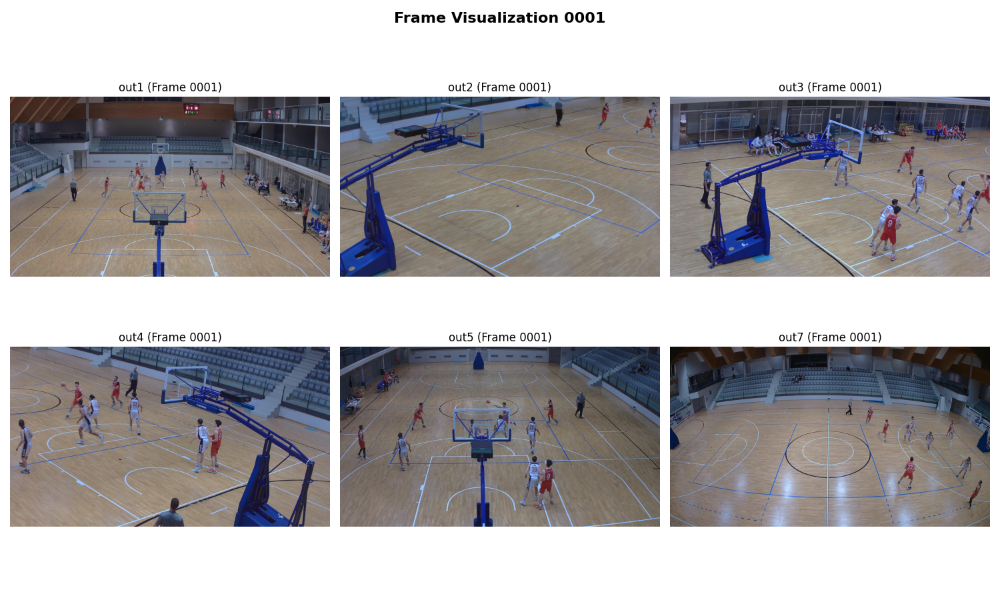

In [19]:
from PIL import Image
BASE_DIR = Path.cwd()

# Relative path to the folder containing the images for visualization
folder_path = BASE_DIR / "dataset_roboflow" / "hpe_01.v1i.coco"
outs_des = ["out1", "out2", "out3", "out4", "out5", "out7"]

# String -> ex: 0001
frame_str = f"{TARGET_FRAME:04d}"

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten() 

for idx, out_name in enumerate(outs_des):
  # Looks for any file that starts with "outX_frame_000Y*"
  pattern = f"{out_name}_frame_{frame_str}*"
  matched_files = list(folder_path.glob(pattern))

  if matched_files:
    # Takes the first file that has that pattern
    img_path = matched_files[0]
    img = Image.open(img_path)

    axes[idx].imshow(img)
    axes[idx].set_title(f"{out_name} (Frame {frame_str})", fontsize=12)
  else:
    # If for that specific prefix any image is found
    axes[idx].text(
        0.5,
        0.5,
        f"Not Found:\n{out_name}",
        ha="center",
        va="center",
        fontsize=12,
    )
    axes[idx].set_title(f"{out_name} - Not Found", fontsize=12)

  axes[idx].axis("off") 

plt.suptitle(
    f"Frame Visualization {frame_str}", fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()


Even more cool would be to look at the frames one after the other, in a GIF like animation, where we plot the 3D real world position of each player looking at the frames sequentially. In order to do so I can just plot sequentially the players using the function `plot_3d_players_on_court` but changing the numer of the frame, from 1 to 5. In order to visualize the GIF more than once in the notebook output we add another for loop.

In [20]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection='3d')

frames_sequence = list(range(1, 6)) * 5  # Repeat frames 1 to 5, five times for a total of 25 frames

def update_3D_all_players(frame, P_dict, K_dict, dist_dict):
    ax.clear()
    
    plot_3d_players_on_court(
        target_players=TARGET_PLAYERS,
        frame_num=frame,
        coco_json_path=COCO_JSON_PATH,
        P_dict=P_dict,
        K_dict=K_dict,
        dist_dict=dist_dict,
        triangulation_func=SELECTED_TRIANGULATION_METHOD,
        ax=ax
    )

anim = FuncAnimation(fig, update_3D_all_players, fargs=(P_dict, K_dict, dist_dict), frames=frames_sequence, interval=150, repeat=False)

# Uncomment to save the animation as a MP4
#anim.save('animation_3d_pre_BA.mp4', writer='ffmpeg', fps=7)

# Close the figure to prevent it from displaying twice in Jupyter Notebook
plt.close(fig)
HTML(anim.to_jshtml())

/tmp/ipykernel_1800/327847197.py:164: MatplotlibDeprecationWarning: The dist attribute was deprecated in Matplotlib 3.6 and will be removed two minor releases later.
  ax.dist = 7      # For older versions


## Reprojection on the image plane
Now that we have reconstructed the 3D real world positions of each joint we want to reproject them into the camera view, in order to visualize how the reconstruction's gone. In this way we see the original image from each camera perspective with the players with their skeleton drawn on them. But since we have rectified the players pixel coordinates we also need to rectify the images on which we are going to reproject the joints, otherwise we applied a transformation to the points but not on the image. We created a folder in which there are all the rectified images. 

Reproject the points is very simple. Given the 3D joint position in homogeneous coordinates $X = \begin{bmatrix} X & Y & Z & 1 \end{bmatrix}^T$, it is sufficient to multiply the camera matrix $P_i \in \mathbb{R}^{3 \times 4}$ of each view by these 3D coordinates:

$$ x_i = P_i X = \begin{bmatrix} p^{1T}_i X \\ p^{2T}_i X \\ p^{3T}_i X \end{bmatrix} = \begin{bmatrix} w \cdot u_i \\ w \cdot v_i \\ w \end{bmatrix} $$

The result will be converted into 2D pixel coordinates $(u_i, v_i)$ representing the position of each joint on the camera plane of that specific camera by dividing by the scale factor $w = p^{3T}_i X$:

$$ u_i = \frac{p^{1T}_i X}{p^{3T}_i X}, \quad v_i = \frac{p^{2T}_i X}{p^{3T}_i X} $$

Let's first extract the 3D coordinates of each joint for all the frames.

In [21]:
TARGET_PLAYERS = ['Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9', 'White_10', 'White_11', 'White_13', 'White_22', 'White_27']
TARGET_FRAMES = [1, 2, 3, 4, 5]

skeleton3d_dict = {}

for frame in TARGET_FRAMES:
    skeleton3d_dict[frame] = {}
    for player in TARGET_PLAYERS:
        keypoints_2d = extract_keypoints_single_frame(COCO_JSON_PATH, player, frame)
        skeleton3d = reconstruct_3d_skeleton(keypoints_2d, P_dict, K_dict, dist_dict, triangulation_function=SELECTED_TRIANGULATION_METHOD)
        skeleton3d_dict[frame][player] = skeleton3d

We have a dictionary in which each player has its 18 3D joint cooridnates for each frame, we can build another dictionary in which, for each camera I will have the 2D coordinates of the joints of each player in each frame. Thus for camera 1 I have 5 frames, for each of these frames 10 players each of which has its own 18 arrays of 2D coordinates. In this way we defined a dictionary that contains all the 2D coordinates of the players in all 6 image planes. 

In [22]:
def project_3d_to_2d(cams, target_frames, target_players, skeleton3d_dict, P_dict):
    '''
    Project 3D coordinates to 2D image space for each camera.

    Args:
        cams (list): List of camera IDs.
        target_frames (list): List of frame numbers.
        target_players (list): List of player names.
        skeleton3d_dict (dict): Dictionary containing 3D skeletons for each frame and player.
        P_dict (dict): Dictionary containing camera projection matrices.

    Returns:
        dict: A nested dictionary where the first key is the camera ID, the second key is the frame number, and the third key is the player name. The value is a numpy array of shape (18, 2) containing the projected 2D coordinates for each joint.
    '''
    points_2d_dict = {}

    for cam in cams:
        points_2d_dict[cam] = {}
        for frame in target_frames:
            points_2d_dict[cam][frame] = {}
            for player in target_players:
                points_3d = np.array(skeleton3d_dict[frame][player])
                
                # Homogeneous coordinates
                ones = np.ones((points_3d.shape[0], 1))
                homo_points = np.hstack([points_3d, ones]) # Add the one to get X = [x, y, z, 1]

                # Project points: x = PX
                homog_result = P_dict[cam] @ homo_points.T
                
                # Normalize to get u, v coordinates
                u = homog_result[0, :] / homog_result[2, :]
                v = homog_result[1, :] / homog_result[2, :]

                points_2d = np.vstack([u, v]).T
                points_2d_dict[cam][frame][player] = points_2d
                
    return points_2d_dict


# --- Example Function call ---
points_2d_dict = project_3d_to_2d(
    cams=['1', '2', '3', '4', '5', '7'],
    target_frames=TARGET_FRAMES,
    target_players=TARGET_PLAYERS,
    skeleton3d_dict=skeleton3d_dict,
    P_dict=P_dict
)

print(f"'points_2d_dict' has {len(points_2d_dict)} cameras, {len(points_2d_dict['5'])} different frames per camera, {len(points_2d_dict['5'][1])} players per frame and {len(points_2d_dict['5'][1]['Red_11'])} 2D coordinates per player")

'points_2d_dict' has 6 cameras, 5 different frames per camera, 10 players per frame and 18 2D coordinates per player


With this dictionary we can project on the image plane of a selected camera and frame the skeletons of each player. The following code is used just for visualization, where one can select a camera, a frame and in the plot we can see the image view from that camera with the skeletons overlapping its the players.

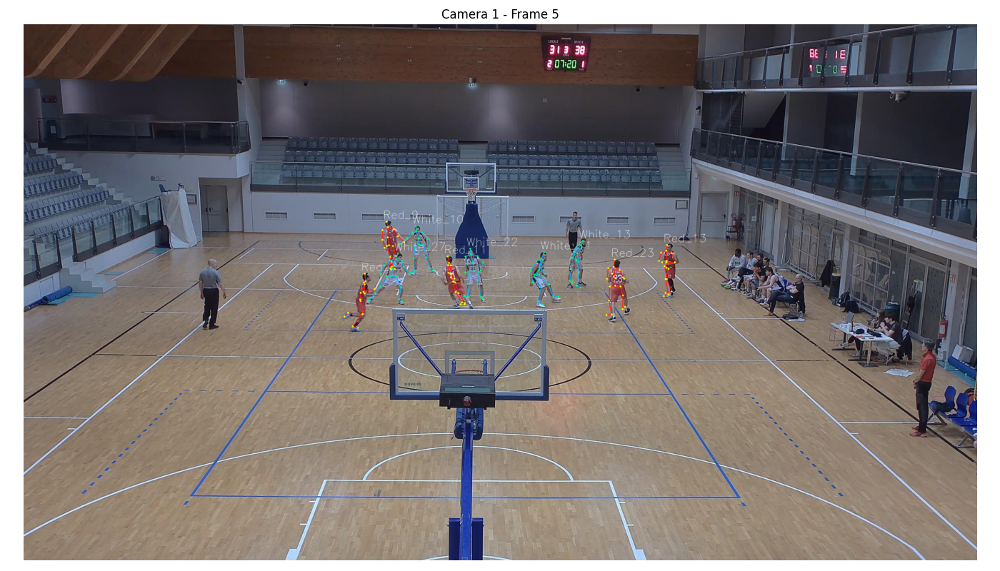

In [23]:
# Configuration
CAM_ID = '1'        # Cam ('1', '2', '3', '4', '5', '7')
TARGET_FRAME = 5    # Frame ('1', '2', '3', '4', '5')

BASE_DIR = Path.cwd()

IMAGE_PATH = BASE_DIR / "rectified_images" / "hpe_rect_01" / f"out{CAM_ID}_0{TARGET_FRAME}.jpg"

TARGET_PLAYERS = ['Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9', 'White_10', 'White_11', 'White_13', 'White_22', 'White_27']

SKELETON_CONNECTIONS = [
    (0, 1),   # Head - Neck
    (1, 2),   # Neck - Right Shoulder
    (1, 3),   # Neck - Left Shoulder
    (2, 4),   # Right Shoulder - Right Elbow
    (4, 6),   # Right Elbow - Right Hand
    (3, 5),   # Left Shoulder - Left Elbow
    (5, 7),   # Left Elbow - Left Hand
    (1, 8),   # Neck - Spine
    (8, 9),   # Spine - Hips
    (9, 10),  # Hips - Right Hip
    (9, 11),  # Hips - Left Hip
    (10, 12), # Right Hip - Right Knee
    (12, 14), # Right Knee - Right Ankle
    (14, 16), # Right Ankle - Right Foot
    (11, 13), # Left Hip - Left Knee
    (13, 15), # Left Knee - Left Ankle
    (15, 17)  # Left Ankle - Left Foot
]


# Load the image
img = cv2.imread(str(IMAGE_PATH))

if img is None:
    raise FileNotFoundError(f"Impossible to load the image: {IMAGE_PATH}")

# Convert BGR in to RGB for MatPlotLib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# SKELETON BUILDING
# Extract the structure of the selected camera
camera_data = points_2d_dict.get(CAM_ID, {})

# Extract data from previous camera data of the selected frame
frame_data = camera_data.get(TARGET_FRAME)

# Loop on all the players
for player in TARGET_PLAYERS:
    # Just a control
    if player not in frame_data:
        continue
    
    joints = frame_data[player]  # List of 18 tuple (x,y) of the selected player

    # Define the RGB colors for the two team players
    if player.startswith('Red'):
        color = (255, 30, 30)       # Red for bones
        joint_color = (255, 255, 0) # Yellow for joints
    else:
        color = (0, 180, 255)      # Light blue for bones
        joint_color = (0, 255, 100) # Green for joints

    # Draw the connections (bones)
    for start_idx, end_idx in SKELETON_CONNECTIONS:
        if start_idx < len(joints) and end_idx < len(joints):
            pt1 = joints[start_idx]
            pt2 = joints[end_idx]

            p1 = (int(round(pt1[0])), int(round(pt1[1])))
            p2 = (int(round(pt2[0])), int(round(pt2[1])))
            cv2.line(img_rgb, p1, p2, color, thickness=2, lineType=cv2.LINE_AA)

    # Draw the points (joints) and also the label of the player
    label_drawn = False
    for pt in joints:
        center = (int(round(pt[0])), int(round(pt[1])))
        cv2.circle(img_rgb, center, radius=3, color=joint_color, thickness=-1, lineType=cv2.LINE_AA)
        
        # Add the name to the first valid point (usually the head)
        if not label_drawn:
            cv2.putText(
                img_rgb, player, (center[0] - 15, center[1] - 12),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 255, 255), 1, cv2.LINE_AA
            )
            label_drawn = True

# PLOT
plt.figure(figsize=(14, 8))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(f"Camera {CAM_ID} - Frame {TARGET_FRAME}")
plt.tight_layout()
plt.show()

To better evaluate the quality of our 3D reconstruction over time, we can create an animation that overlays the reprojected skeletons onto the sequence of recorded images frame by frame. By simply changing the camera ID, we can inspect the motion sequence from any available camera perspective.

In [24]:
def create_skeleton_animation(cam_id, target_frames, points_2d_dict, target_players, base_dir):
    """
    Generates an HTML5 video animation of 2D skeletons overlaid on camera frames.

    Args:
        cam_id (str): The camera ID to visualize.
        target_frames (list): List of frame numbers to include in the animation.
        points_2d_dict (dict): Nested dictionary containing 2D skeleton coordinates for each camera, frame, and player.
        target_players (list): List of player names to visualize.
        base_dir (Path): Base directory containing the rectified images.
    
    Returns:
        HTML: An HTML5 video animation of the skeletons overlaid on the camera frames.
    """


    # Set up matplotlib figure
    fig, ax = plt.subplots(figsize=(14, 8))

    def update_anim_vid(frame_num):
        ax.clear()
        
        # Load the image for the current frame
        image_path = base_dir / "rectified_images" / "hpe_rect_01" / f"out{cam_id}_0{frame_num}.jpg"
        img = cv2.imread(str(image_path))
        
        if img is None:
            print(f"[WARNING] Impossible to load image: {image_path}")
            return
        
        # Convert BGR into RGB for MatPlotLib
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # --- SKELETON BUILDING ---
        camera_data = points_2d_dict.get(cam_id, {})
        frame_data = camera_data.get(frame_num, {})
        
        # Loop on all the players
        for player in target_players:
            if player not in frame_data:
                continue
                
            joints = frame_data[player]  # List of 2D reprojected coordinates
            
            # Define the RGB colors for the two team players
            if player.startswith('Red'):
                color = (255, 30, 30)       # Red for bones
                joint_color = (255, 255, 0) # Yellow for joints
            else:
                color = (0, 180, 255)       # Light blue for bones
                joint_color = (0, 255, 100) # Green for joints
                
            # Draw the connections (bones)
            for start_idx, end_idx in SKELETON_CONNECTIONS:
                if start_idx < len(joints) and end_idx < len(joints):
                    pt1 = joints[start_idx]
                    pt2 = joints[end_idx]
                    
                    if not (np.isnan(pt1).any() or np.isnan(pt2).any()):
                        p1 = (int(round(pt1[0])), int(round(pt1[1])))
                        p2 = (int(round(pt2[0])), int(round(pt2[1])))
                        cv2.line(img_rgb, p1, p2, color, thickness=5, lineType=cv2.LINE_AA)
                        
            # Draw the points (joints) and also the label of the player
            label_drawn = False
            for pt in joints:
                if np.isnan(pt).any():
                    continue
                center = (int(round(pt[0])), int(round(pt[1])))
                cv2.circle(img_rgb, center, radius=7, color=joint_color, thickness=-1, lineType=cv2.LINE_AA)
                
                # Add the name to the first valid point (usually the head)
                if not label_drawn:
                    cv2.putText(
                        img_rgb, player, (center[0] - 15, center[1] - 12),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 255, 255), 1, cv2.LINE_AA
                    )
                    label_drawn = True

        # Plot layout configuration
        ax.imshow(img_rgb)
        ax.axis('off')
        ax.set_title(f"Camera {cam_id} - Frame {frame_num}", fontsize=14)

    # Create the animation over the target frames
    anim = FuncAnimation(fig, update_anim_vid, frames=target_frames, interval=400, repeat=True)

    # Close static figure and render HTML5 widget player
    plt.close(fig)

    # Uncomment the following line to save the animation as an MP4 file
    #anim.save('skeletons_anim.mp4', writer='ffmpeg', fps=10)

    return HTML(anim.to_jshtml())


# --- USAGE EXAMPLE ---

# Configuration
CAM_ID = '5'        # Cam ('1', '2', '3', '4', '5', '7')
TARGET_FRAMES = list(range(1, 6))
BASE_DIR = Path.cwd()
TARGET_PLAYERS = ['Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9', 'White_10', 'White_11', 'White_13', 'White_22', 'White_27']

# Call the function and display the output (in Jupyter Notebook / Colab)
animation_html = create_skeleton_animation(CAM_ID, TARGET_FRAMES, points_2d_dict, TARGET_PLAYERS, BASE_DIR)
display(animation_html)

**NOTE:** the camera view-point visualized can be changed by modifying: `CAM_ID = 'i'`

We can already see that in some cases the reprojected skeletons fit well on the correspondent player, while in some others they don't, they are shifted or in other cases the joints and bones are not well aligned with the player's. But we want to find a way to see numerically these results, how these reprojected points fit the player's but with numbers and not just by visualisation. In order to do so, we may compare for each image and each frame the reprojected points with the ground truth from the coco annotations file, it is very important to rectify even the ground truth annotated points otherwise we would compare rectieifed points with not. First of all, let's get things in order.

Structure of the dictionaries of the points:

- REPROJECTED: `points_2d_dict[camera][frame][player]` returns `(18,2)`, thus 18 couples of x,y coordinates of the joints
- GROUND TRUTH: `keypoints_2d_dict[frame][player][camera]` returns `54` (18*3 since we have x,y,v for each joint) elements

In [25]:
keypoints_2d_dict = {}

for frame in TARGET_FRAMES:
    keypoints_2d_dict[frame] = {}
    
    for player in TARGET_PLAYERS:
        # Extract the cam dictionary {'1': [54 elem], '2': [54 elem], ...}
        keypoints_2d = extract_keypoints_single_frame(COCO_JSON_PATH, player, frame)
        
        rectified_cameras_dict = {}
        
        # Cycle on the cams for that player
        for cam_id, kp_54 in keypoints_2d.items():
            # Control for cam indexing
            K = K_dict.get(cam_id) if cam_id in K_dict else K_dict.get(int(cam_id))
            dist = dist_dict.get(cam_id) if cam_id in dist_dict else dist_dict.get(int(cam_id))
            
            rectified_kp = rectify_skeleton(kp_54, K, dist)
            rectified_cameras_dict[cam_id] = np.concatenate(rectified_kp).tolist()
        
        # Save the rectified points in the dictionary
        keypoints_2d_dict[frame][player] = rectified_cameras_dict


# reprojected_points[camera][frame][player]
reprojected_points = points_2d_dict
# gt_points[frame][player][camera]
gt_points = keypoints_2d_dict

### Mean per joint poisition error (MPE)

In order to compare the reprojected points and the ground truth one can use different metrics, let's use the mean per joint position error, where we simply compute the Euclidian distance pixel by pixel. Imagine that $\hat{p}_i=(\hat{x}_i,\hat{y}_i)$ is the 2D i-th reprojected point and $p_i=(x_i, y_i)$ is the 2D ground truth i-th point. We can compute the reprojection error as:

$$\text{error}=\frac{1}{N} \sum _{i=1}^N \sqrt{(\hat{x}_i-x_i)^2+(\hat{y}_i-y_i)^2}$$

Where N is the number of joints per player.

We can implement a function `compute_skeleton_pixel_error` that takes the 2D points of the ground truth and the reprojected ones of a certain skeleton (i.e. given a certain frame, camera and player) and compute the mean per joint error for the entire skeleton. It parse the ground truth, considering that it has also the visibility parameter and then considers only the visible joints. Finally it computes the Euclidian distance between the ground truth visible points and the reprojected ones. It returns the mean of the errors of all the skeleton joints. After defining the function for the computation of the mean reprojection error for a selected skeleton I can build a dictionary `results` in which we can store the results of a selected frame for all the cameras and all the players. 

In [26]:
# Selected frame
FRAME_ID = 1

# Function to compute the error on the single skeleton
def compute_skeleton_pixel_error(gt_raw, reproj_pts):
    """
    Compute the mean pixel error between the GT and the reprojection for a single skeleton

    args:
        gt_raw: list of 54 elements (x, y, v) for the GT
        reproj_pts: list of 18 tuples (x, y) for the reprojected points

    returns:
        mean pixel error (float) or None if no valid points are found
    """
    if gt_raw is None or reproj_pts is None:
        return None
    
    gt_pts = []
    visibility = []
    
    # Parsing GT (x, y, v)
    for i in range(0, len(gt_raw), 3):
        gt_pts.append([gt_raw[i], gt_raw[i + 1]])
        visibility.append(gt_raw[i + 2])
        
    gt_pts = np.array(gt_pts)
    visibility = np.array(visibility)
    reproj_pts = np.array(reproj_pts)
    
    # Build a mask for only the visible joints
    valid_mask = visibility > 0
    if np.sum(valid_mask) == 0:
        return None
        
    gt_valid = gt_pts[valid_mask]
    reproj_valid = reproj_pts[valid_mask]
    
    # Compute Euclidian distance for each joint
    per_joint_errors = np.linalg.norm(reproj_valid - gt_valid, axis=1)
    
    return np.mean(per_joint_errors)

In [27]:
# I create an helper function to render the evaluation tables for each frame and an overall summary for the different error metrics

def render_evaluation_tables(df, metric_col, value_format, base_title):
    """Renders pivot tables for individual frames and an overall summary.

    Computes Micro-averages for row means, column means, and overall
    totals directly from the underlying datase.

    Args:
        df (pd.DataFrame): Dataset containing ['Frame', 'Camera', 'Player',
          metric_col].
        metric_col (str): The column name containing the evaluation metric.
        value_format (str): String format for the values (e.g., "{:.2f} cm",
          "{:.4f}").
        base_title (str): The core title used for the tables.
    """
    # Fallback if DataFrame is empty or missing
    if df is None or df.empty:
        print(f"[INFO] No valid data found for {base_title}.")
        return

    # Extract available unique frames directly from the DataFrame
    available_frames = sorted(df["Frame"].unique())

    # Helper nested function to compute micro-means, style, and display tables
    def style_and_display(df_source, pivot_df, title):
        pivot_with_means = pivot_df.copy()

        # 1. Compute true Micro-averages directly from the source DataFrame
        player_means = df_source.groupby("Player")[metric_col].mean()
        camera_means = df_source.groupby("Camera")[metric_col].mean()
        overall_mean = df_source[metric_col].mean()

        # 2. Assign the computed micro-means to marginal rows and columns
        pivot_with_means["PLAYER MEAN"] = player_means
        pivot_with_means.loc["CAMERA MEAN"] = camera_means

        # 3. Explicitly set the bottom-right corner to the true overall micro-mean
        pivot_with_means.loc["CAMERA MEAN", "PLAYER MEAN"] = overall_mean

        # 4. Format and apply CSS styling dynamically
        mean_str = value_format.format(overall_mean)
        styled = (
            pivot_with_means.style.format(value_format)
            .set_caption(f"<b>{title}</b>")
            .set_table_styles(
                [{"selector": "caption", "props": [("font-size", "16px")]}]
            )
        )

        # 5. Display the styled table and the mean score label
        display(styled)
        display(HTML(f"<b> Mean Score: {mean_str}</b><br><br><hr>"))

    # 1. Render individual table for each frame
    for frame_id in available_frames:
        df_frame = df[df["Frame"] == frame_id]
        if not df_frame.empty:
            pivot_frame = df_frame.pivot(
                index="Player", columns="Camera", values=metric_col
            )
            style_and_display(
                df_frame, pivot_frame, f"{base_title} - Frame {frame_id}"
            )

    # 2. Render overall summary table across all frames
    display(HTML(f"<h2> OVERALL SUMMARY ({base_title.upper()})</h2>"))
    pivot_overall = df.pivot_table(
        index="Player", columns="Camera", values=metric_col, aggfunc="mean"
    )

    # Pass the complete DataFrame to compute true global micro-averages across all frames
    style_and_display(
        df, pivot_overall, f"Mean {base_title} - Overall (All Frames)"
    )

In [28]:
# Now i can call the function to render the evaluation tables for the pixel error metric
# 1. Collect pixel errors across all available frames, cameras, and players
AVAILABLE_FRAMES = [1, 2, 3, 4, 5]

import pandas as pd

def evaluate_metric(reprojected_points, gt_points, metric_func, metric_name="Score", available_frames=None, pass_context=False):
    """
    Evaluates a given metric across all cameras, frames, and players.

    Args:
        reprojected_points (dict): Nested dictionary containing reprojected 2D points for each camera, frame, and player.
        gt_points (dict): Nested dictionary containing ground truth 2D points for each frame, player, and camera.
        metric_func (callable): A function that computes the metric given ground truth and reprojected points.
        metric_name (str): The name of the metric to be used in the resulting DataFrame.
        available_frames (list, optional): List of frame numbers to evaluate. If None, all frames in reprojected_points will be used.
        pass_context (bool): If True, passes additional context (camera ID, frame ID, player name) to the metric function. This is needed to handle the CM-error metric which requires camera-specific parameters.
    
    Returns:
        pd.DataFrame: A DataFrame containing the evaluation results with columns ['Frame', 'Camera', 'Player', metric_name].
    """
    records = []

    for cam_id, cam_data in reprojected_points.items():
        frames_to_process = available_frames if available_frames is not None else cam_data.keys()

        for frame_id in frames_to_process:
            if frame_id not in cam_data:
                continue

            for player_name, reproj_pts in cam_data[frame_id].items():
                gt_frame_data = gt_points.get(frame_id, gt_points.get(int(frame_id), {}))
                gt_player_data = gt_frame_data.get(player_name, {})
                gt_raw = gt_player_data.get(str(cam_id), gt_player_data.get(int(cam_id)))

                if gt_raw is not None:
                    # NEW: Pass context variables if the metric requires them
                    if pass_context:
                        val = metric_func(gt_raw, reproj_pts, cam_id, frame_id, player_name)
                    else:
                        val = metric_func(gt_raw, reproj_pts)
                    
                    if val is not None:
                        records.append({
                            "Frame": frame_id,
                            "Camera": f"Cam {cam_id}",
                            "Player": player_name,
                            metric_name: val
                        })

    return pd.DataFrame(records)


# Evaluate the pixel error metric across all cameras, frames, and players
df_px = evaluate_metric(
    reprojected_points, 
    gt_points, 
    compute_skeleton_pixel_error, 
    metric_name="Error PX",
    available_frames=AVAILABLE_FRAMES
)

# Helper function to render evaluation tables for the pixel error metric
render_evaluation_tables(
    df=df_px, 
    metric_col="Error PX", 
    value_format="{:.2f} px", 
    base_title="Reprojection Pixel Error (MPE)"
)

Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,12.01 px,28.21 px,65.73 px,21.56 px,22.20 px,31.11 px,30.14 px
Red_13,12.43 px,nan px,18.07 px,nan px,68.86 px,88.82 px,47.04 px
Red_23,16.11 px,nan px,22.05 px,nan px,41.00 px,39.45 px,29.65 px
Red_7,7.14 px,5.43 px,nan px,9.38 px,29.07 px,6.11 px,11.43 px
Red_9,8.42 px,nan px,29.40 px,21.24 px,34.43 px,54.46 px,29.59 px
White_10,11.56 px,nan px,24.38 px,20.70 px,25.83 px,29.68 px,22.43 px
White_11,23.43 px,nan px,22.38 px,30.30 px,28.32 px,31.61 px,27.21 px
White_13,9.07 px,nan px,15.24 px,14.52 px,56.44 px,39.88 px,27.03 px
White_22,13.04 px,nan px,28.36 px,18.59 px,14.83 px,37.47 px,22.46 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,10.97 px,24.69 px,35.96 px,23.54 px,25.94 px,25.03 px,24.36 px
Red_13,12.44 px,nan px,15.87 px,nan px,68.72 px,84.50 px,45.38 px
Red_23,16.06 px,nan px,21.54 px,nan px,41.36 px,44.40 px,30.84 px
Red_7,8.43 px,5.82 px,nan px,14.40 px,35.65 px,7.28 px,14.32 px
Red_9,12.27 px,nan px,29.23 px,21.21 px,39.86 px,59.51 px,32.42 px
White_10,9.42 px,nan px,27.74 px,20.18 px,22.60 px,30.22 px,22.03 px
White_11,12.87 px,nan px,18.28 px,14.27 px,18.46 px,16.97 px,16.17 px
White_13,10.09 px,nan px,17.18 px,14.42 px,57.78 px,36.16 px,27.13 px
White_22,12.08 px,nan px,25.80 px,16.35 px,16.64 px,36.70 px,21.51 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,11.61 px,nan px,31.77 px,14.64 px,15.37 px,22.71 px,19.22 px
Red_13,12.02 px,nan px,17.85 px,nan px,69.52 px,88.98 px,47.09 px
Red_23,15.22 px,nan px,19.01 px,nan px,38.93 px,52.75 px,31.48 px
Red_7,6.81 px,8.14 px,nan px,15.22 px,37.98 px,8.01 px,15.23 px
Red_9,10.86 px,nan px,29.16 px,19.88 px,41.66 px,60.41 px,32.40 px
White_10,11.07 px,nan px,23.60 px,17.49 px,37.90 px,30.25 px,24.06 px
White_11,9.21 px,nan px,18.13 px,15.35 px,17.71 px,20.64 px,16.21 px
White_13,9.07 px,nan px,16.03 px,14.70 px,59.95 px,35.39 px,27.03 px
White_22,14.56 px,nan px,21.09 px,29.22 px,30.54 px,29.49 px,24.98 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,21.20 px,nan px,34.02 px,33.64 px,27.94 px,33.55 px,30.07 px
Red_13,12.69 px,nan px,14.01 px,nan px,69.91 px,97.11 px,48.43 px
Red_23,15.14 px,nan px,29.42 px,nan px,50.11 px,52.12 px,36.70 px
Red_7,7.93 px,8.85 px,nan px,13.81 px,30.71 px,9.37 px,14.13 px
Red_9,12.19 px,nan px,29.61 px,16.06 px,48.05 px,56.67 px,32.52 px
White_10,10.51 px,nan px,23.91 px,16.49 px,36.44 px,32.63 px,23.99 px
White_11,11.28 px,nan px,16.40 px,11.45 px,24.11 px,25.47 px,17.74 px
White_13,8.82 px,nan px,15.88 px,11.49 px,55.06 px,33.10 px,24.87 px
White_22,13.08 px,nan px,32.54 px,20.27 px,30.55 px,48.79 px,29.05 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,31.22 px,nan px,45.22 px,46.09 px,58.97 px,32.45 px,42.79 px
Red_13,14.25 px,nan px,17.22 px,nan px,80.86 px,91.39 px,50.93 px
Red_23,14.48 px,nan px,27.40 px,nan px,47.89 px,55.83 px,36.40 px
Red_7,6.40 px,8.53 px,nan px,11.65 px,30.92 px,11.68 px,13.83 px
Red_9,14.27 px,nan px,23.32 px,20.09 px,57.09 px,39.07 px,30.77 px
White_10,11.44 px,nan px,22.53 px,18.59 px,43.00 px,29.02 px,24.92 px
White_11,10.30 px,nan px,20.70 px,12.87 px,33.87 px,30.21 px,21.59 px
White_13,16.26 px,nan px,50.99 px,25.66 px,62.21 px,85.97 px,48.22 px
White_22,13.03 px,nan px,26.61 px,18.84 px,27.41 px,38.12 px,24.80 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,17.40 px,26.45 px,42.54 px,27.89 px,30.08 px,28.97 px,29.16 px
Red_13,12.76 px,nan px,16.60 px,nan px,71.57 px,90.16 px,47.78 px
Red_23,15.40 px,nan px,23.88 px,nan px,43.86 px,48.91 px,33.01 px
Red_7,7.34 px,7.35 px,nan px,12.89 px,32.86 px,8.49 px,13.79 px
Red_9,11.60 px,nan px,28.14 px,19.69 px,44.22 px,54.03 px,31.54 px
White_10,10.80 px,nan px,24.43 px,18.69 px,33.15 px,30.36 px,23.49 px
White_11,13.42 px,nan px,19.18 px,16.85 px,24.49 px,24.98 px,19.78 px
White_13,10.66 px,nan px,23.06 px,16.16 px,58.28 px,46.10 px,30.85 px
White_22,13.16 px,nan px,26.88 px,20.65 px,23.99 px,38.11 px,24.56 px


In these results we can see the MPE for each player in each camera and we also see the average error of each camera. The camera that achieved the top performance is the first camera with an average error of 12.14 pixels, while the worst is the seventh and the fifth with 38.34 and pixels. The error of the latter two is probably due to the fact that some players are at the borders of the image, e.g. 'Red_13', and the rectification may have influenced the results, for example because camera 7 have a strong "fish eye" effect. Probably aslo the quality of the annotaions strongly affects the overall quality.

Another interesting thing to look at, is the mean of the errors of the players, with that we can understand if the position of the players on the court may influence or not the errors. This informations asre shown in the last column of the tables.

As we can see from these results, there are some players, like 'Red_7' with 13.79 pixels error, that have a small error, and others, like 'Red_13' with 47.78 pixels error. This could be again due to the same problem seen above, where 'Red_13' in camera 7 had big error and it made the mean error grow. This is due to the fact that 'Red_13' is positioned on the borders of the court and is also seen from 4 cameras only. 

### Object Keypoint Similarity
Another factor to take into account is that the more a player is close to a camera the more it will be penalised with this metric. We can use the OKS in order to consider this, here follows a brief math explanation of how it works. 

$$OKS=\frac{\sum_i \exp(-d_i^2/(2s^2k_i^2))\cdot v_i}{\sum_i v_i}$$

where:
* $d_i$: is the Euclidian distance that we have already computed;
* $s$: is the scale of the player ($\sqrt{\text{bounding box area}}$);
* $k_i$: joint tollerance constant;
* $v_i$: visibility flag of the GT.

In this way we take into account also the distance of the players from the camera, thus they are not penalised if closer to cameras. $K_i$ is avoiding that the small points (like the head) are evaluated with the same tollerance of bigger points (like the spine). We use a big penalisation on smaller points (0.026 for head and neck) and less severe on bigger points (0.107 for spine and hips). 

For more see: https://cocodataset.org/#keypoints-eval

Then we define a function, `calculate_oks_single_skeleton`, where we compute the OKS of a given skeleton between the ground truth and the reprojected one. This function takes a list of 54 elements from the ground truth as `[x1, y1, v1, x2, y2, v2, ...]` and a list of 18 tuples from the reprojected points as `[[x1, y1], [x2, y2], ...]`. Then as previously done, we parse the ground truth to split the coordinates from the visibility coefficient and compute the mask to highlight the visible joints. It computes the scale $s$ from the area of the bounding boxes of the gt skeleton, computes the Euclidian distance and finally computes the OKS score.

After the OKS function definition we can then define a dictionary (`oks_results`) in which we are going to store the OKS results of all the skeletons. With three nested loops, one for the cams, one for frames and another for payers it computes the OKS score for all the players in all the frames and all the camera views. 

Finally we can print some results, considering that the more the OKS result is close to 1 the more the reprojected skeleton is accurate with respect to the ground truth one, the more instead is close to 0, the bad is the reconstruction. 

In [29]:
# Define the joint tollerance constants
# Pesa con tolleranza minore la testa e con tolleranza maggiore i piedi/arti
# Low weights to the head and higher tollerance to feet and limbs
K_I = np.array([
    0.026,  # 0: Head
    0.026,  # 1: Neck
    0.079,  # 2: R Shoulder
    0.079,  # 3: L Shoulder
    0.072,  # 4: R Elbow
    0.072,  # 5: L Elbow
    0.062,  # 6: R Hand
    0.062,  # 7: L Hand
    0.107,  # 8: Spine
    0.107,  # 9: Hips
    0.089,  # 10: R Hip
    0.089,  # 11: L Hip
    0.087,  # 12: R Knee
    0.087,  # 13: L Knee
    0.089,  # 14: R Ankle
    0.089,  # 15: L Ankle
    0.089,  # 16: R Foot
    0.089   # 17: L Foot
])


def calculate_oks_single_skeleton(gt_raw, reproj_pts):
    """
    Compute the OKS between a gt skeleton and a reprojected one.
    
    gt_raw: list of 54 elements [x1, y1, v1, x2, y2, v2, ...]
    reproj_pts: list of 18 tuples [[x1, y1], [x2, y2], ...]
    """
    if gt_raw is None or reproj_pts is None:
        return None

    # Parsing Ground Truth
    gt_pts = []
    visibility = []
    for i in range(0, len(gt_raw), 3):
        gt_pts.append([gt_raw[i], gt_raw[i + 1]])
        visibility.append(gt_raw[i + 2])

    gt_pts = np.array(gt_pts)           # Shape (18, 2)
    visibility = np.array(visibility)   # Shape (18,)
    reproj_pts = np.array(reproj_pts)   # Shape (18, 2)

    # Consider only visible points from the ground truth
    valid_mask = visibility > 0
    if np.sum(valid_mask) == 0:
        return None

    # Compute the scale s (area of the bounding box)
    valid_gt_pts = gt_pts[valid_mask]
    x_min, y_min = np.min(valid_gt_pts, axis=0)
    x_max, y_max = np.max(valid_gt_pts, axis=0)
    
    area = (x_max - x_min) * (y_max - y_min)
    scale = np.sqrt(area) if area > 0 else 1.0  # s = sqrt(area)

    # Compute the Euclidian distances and its squared
    dists_sq = np.sum((reproj_pts - gt_pts) ** 2, axis=1)  # Shape (18,)

    # OKS for each keypoint: exp(-d_i^2 / (2 * s^2 * k_i^2))
    vars_i = (2.0 * (scale ** 2) * (K_I ** 2))
    oks_per_keypoint = np.exp(-dists_sq / vars_i)

    # Weighted sum on the visible points
    oks_score = np.sum(oks_per_keypoint * valid_mask) / np.sum(valid_mask)
    
    return oks_score


# Call the evaluation function to compute the OKS metric across all cameras, frames, and players
df_oks = evaluate_metric(
    reprojected_points, 
    gt_points, 
    calculate_oks_single_skeleton, 
    metric_name="OKS",
    available_frames=AVAILABLE_FRAMES
)

# Call the helper function to render the evaluation tables for the OKS metric
render_evaluation_tables(
    df=df_oks, 
    metric_col="OKS", 
    value_format="{:.4f}", 
    base_title="Object Keypoint Similarity (OKS)"
)

Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.7004,0.5521,0.1622,0.6838,0.6639,0.2705,0.5055
Red_13,0.4058,nan,0.4546,nan,0.0192,0.0594,0.2348
Red_23,0.3793,nan,0.5020,nan,0.1065,0.2689,0.3142
Red_7,0.7923,0.9287,nan,0.8234,0.2413,0.7959,0.7163
Red_9,0.6245,nan,0.6564,0.6162,0.4358,0.1440,0.4954
White_10,0.5308,nan,0.7073,0.7606,0.6784,0.2457,0.5846
White_11,0.4422,nan,0.6377,0.6374,0.5183,0.3725,0.5216
White_13,0.6391,nan,0.7527,0.8176,0.0746,0.3613,0.5290
White_22,0.4650,nan,0.5229,0.6164,0.7132,0.2858,0.5207


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.6271,0.3247,0.1979,0.5865,0.4100,0.3157,0.4104
Red_13,0.4672,nan,0.5965,nan,0.0493,0.1367,0.3124
Red_23,0.4656,nan,0.5500,nan,0.1295,0.2562,0.3503
Red_7,0.7860,0.8950,nan,0.7461,0.2088,0.7381,0.6748
Red_9,0.4682,nan,0.6530,0.6417,0.3781,0.0682,0.4419
White_10,0.6762,nan,0.6961,0.7521,0.7495,0.3076,0.6363
White_11,0.4210,nan,0.6977,0.8439,0.7191,0.5212,0.6406
White_13,0.5737,nan,0.7096,0.7822,0.0782,0.4124,0.5112
White_22,0.5500,nan,0.5630,0.7435,0.6256,0.3408,0.5646


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.5834,nan,0.3461,0.7623,0.6279,0.3734,0.5386
Red_13,0.4459,nan,0.5013,nan,0.0211,0.0668,0.2587
Red_23,0.4463,nan,0.5818,nan,0.0961,0.1964,0.3301
Red_7,0.8161,0.8472,nan,0.7178,0.1316,0.6536,0.6332
Red_9,0.5739,nan,0.6660,0.6640,0.3960,0.0725,0.4745
White_10,0.6061,nan,0.7309,0.8134,0.5525,0.3574,0.6120
White_11,0.7449,nan,0.6843,0.8692,0.6606,0.5043,0.6927
White_13,0.5622,nan,0.7103,0.8347,0.0481,0.3730,0.5057
White_22,0.4462,nan,0.5583,0.4113,0.2473,0.2460,0.3818


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.4189,nan,0.3777,0.4924,0.3840,0.2966,0.3939
Red_13,0.3778,nan,0.7158,nan,0.0166,0.0422,0.2881
Red_23,0.4476,nan,0.2989,nan,0.0504,0.2050,0.2505
Red_7,0.7992,0.8565,nan,0.7037,0.2162,0.6559,0.6463
Red_9,0.5592,nan,0.6934,0.7717,0.3565,0.0992,0.4960
White_10,0.6607,nan,0.7690,0.8445,0.5811,0.2891,0.6289
White_11,0.4776,nan,0.6571,0.8186,0.4040,0.3857,0.5486
White_13,0.5289,nan,0.7070,0.8451,0.0559,0.4116,0.5097
White_22,0.5102,nan,0.4588,0.6690,0.4784,0.3722,0.4977


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.1565,nan,0.1804,0.3271,0.1363,0.3014,0.2203
Red_13,0.2826,nan,0.6370,nan,0.0144,0.0771,0.2528
Red_23,0.4003,nan,0.4708,nan,0.0822,0.2419,0.2988
Red_7,0.8423,0.8543,nan,0.7052,0.0869,0.5927,0.6163
Red_9,0.4185,nan,0.7372,0.6979,0.1701,0.1498,0.4347
White_10,0.6197,nan,0.7973,0.8054,0.4672,0.3033,0.5986
White_11,0.6517,nan,0.6554,0.8354,0.3470,0.4141,0.5807
White_13,0.1901,nan,0.2168,0.6214,0.1634,0.0719,0.2527
White_22,0.4765,nan,0.4618,0.7203,0.2951,0.3950,0.4698


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.4973,0.4384,0.2529,0.5704,0.4444,0.3115,0.4170
Red_13,0.3959,nan,0.5810,nan,0.0241,0.0764,0.2694
Red_23,0.4278,nan,0.4807,nan,0.0929,0.2337,0.3088
Red_7,0.8072,0.8763,nan,0.7392,0.1770,0.6872,0.6574
Red_9,0.5289,nan,0.6812,0.6783,0.3473,0.1067,0.4685
White_10,0.6187,nan,0.7401,0.7952,0.6057,0.3006,0.6121
White_11,0.5475,nan,0.6664,0.8009,0.5298,0.4396,0.5968
White_13,0.4988,nan,0.6193,0.7802,0.0840,0.3260,0.4617
White_22,0.4896,nan,0.5130,0.6321,0.4719,0.3280,0.4869


Again we can see that the worst are camera 7 and 5, where in some cases ('Red_13') the score is close to zero, meaning that the reconstruction in that case is very bad. However, the best score is achieved by the camera 4 and camera 1, indeed if we go to see above, the distance of the view of these two camera are different, the first camera is positioned on the opposite side of the court while the fourth is in the same, this means that the OKS metric is considering the distance from the player, because now the best is camera 4 and no more 1.

In [30]:
def compute_err_cm(gt_raw, reproj_pts, points_3d, K_matrix, P_matrix):
  """
  Computes reprojection error in centimeters by scaling pixel distance 
  according to joint depth (Z) and camera focal length (fx).

  Args:
    gt_raw: list of 54 elements (x, y, v) for the GT
    reproj_pts: list of 18 tuples (x, y) for the reprojected points
    points_3d: list of 18 tuples (X, Y, Z) for the 3D points
    K_matrix: 3x3 camera intrinsic matrix
    P_matrix: 3x4 camera projection matrix
    
  Returns:
    Mean reprojection error in centimeters (float) or None if no valid points are found
  """
  #Fallback
  if gt_raw is None or reproj_pts is None or points_3d is None:
    return None

  gt_pts, visibility = [], []
  for i in range(0, len(gt_raw), 3):
    gt_pts.append([gt_raw[i], gt_raw[i + 1]])
    visibility.append(gt_raw[i + 2])

  gt_pts = np.array(gt_pts)
  visibility = np.array(visibility)
  reproj_pts = np.array(reproj_pts)
  points_3d = np.array(points_3d)

  # Create a mask for visible joints, ckeck for NaN values in reproj_pts and points_3d and if the point is visible
  # This command creates a boolean array of true/false values 
  valid_mask = (visibility > 0) & ~np.isnan(reproj_pts[:, 0]) & ~np.isnan(points_3d[:, 0]) 
  
  # Fallback if no valid points are found
  if np.sum(valid_mask) == 0:
    return None

  # Ghe the valid points by indexing with the valid_mask
  gt_valid = gt_pts[valid_mask]
  reproj_valid = reproj_pts[valid_mask]
  pts_3d_valid = points_3d[valid_mask]

  # 1. Focal length in pixels (fx)
  fx = K_matrix[0, 0]
  
  # 2. Homogeneous 3D points to calculate depth Z (w) in camera space
  ones = np.ones((pts_3d_valid.shape[0], 1))
  homo_3d = np.hstack([pts_3d_valid, ones])

  # depth Z_cam = p3^T * X_world
  depth_z = (P_matrix[2, :] @ homo_3d.T)  # Shape (N,)
  
  # 3. Compute 2D pixel distance for each joint
  pixel_errors = np.linalg.norm(reproj_valid - gt_valid, axis=1)
  
  # 4. Convert pixel error to cm: (err_px * Z_mm / fx_px) / 10
  cm_errors = (pixel_errors * depth_z / fx) / 10.0
  
  return np.mean(cm_errors)


# Compute CM errors
df_cm = evaluate_metric(
    reprojected_points, 
    gt_points, 
    metric_func=lambda gt, reproj, c_id, f_id, p_name: compute_err_cm(
        gt,     # 2D Ground truth points
        reproj, # 3D reprojected points
        points_3d=skeleton3d_dict[f_id][p_name],  # skeleton in frame f_id of player p_name
        K_matrix=K_dict.get(c_id, K_dict.get(int(c_id))),  # K matrix for cam c_id
        P_matrix=P_dict.get(c_id, P_dict.get(int(c_id)))   # P matrix for cam c_id
    ),
    metric_name="Error (cm)",
    available_frames=AVAILABLE_FRAMES,
    pass_context=True  
)

# Call the helper function to render the evaluation tables for the reprojection error in centimeters
render_evaluation_tables(
    df=df_cm, 
    metric_col="Error (cm)", 
    value_format="{:.2f} cm", 
    base_title="Reprojection Error in CM"
)

Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,8.63 cm,14.12 cm,24.70 cm,8.49 cm,10.94 cm,20.07 cm,14.49 cm
Red_13,10.13 cm,nan cm,8.11 cm,nan cm,26.72 cm,29.11 cm,18.52 cm
Red_23,11.61 cm,nan cm,10.10 cm,nan cm,19.83 cm,16.85 cm,14.60 cm
Red_7,4.97 cm,2.84 cm,nan cm,4.12 cm,14.95 cm,4.60 cm,6.29 cm
Red_9,7.59 cm,nan cm,8.05 cm,6.52 cm,10.50 cm,36.55 cm,13.84 cm
White_10,10.33 cm,nan cm,6.88 cm,6.32 cm,8.03 cm,19.21 cm,10.15 cm
White_11,18.79 cm,nan cm,8.16 cm,10.02 cm,11.56 cm,18.20 cm,13.35 cm
White_13,7.58 cm,nan cm,6.10 cm,3.89 cm,20.76 cm,16.97 cm,11.06 cm
White_22,9.94 cm,nan cm,10.26 cm,6.76 cm,6.64 cm,23.60 cm,11.44 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,7.93 cm,12.22 cm,13.77 cm,9.04 cm,12.61 cm,15.52 cm,11.85 cm
Red_13,10.15 cm,nan cm,7.17 cm,nan cm,26.63 cm,27.17 cm,17.78 cm
Red_23,11.61 cm,nan cm,9.89 cm,nan cm,19.93 cm,18.71 cm,15.03 cm
Red_7,5.83 cm,3.02 cm,nan cm,6.34 cm,18.52 cm,5.49 cm,7.84 cm
Red_9,11.06 cm,nan cm,8.00 cm,6.50 cm,12.12 cm,39.68 cm,15.47 cm
White_10,8.44 cm,nan cm,7.84 cm,6.10 cm,6.99 cm,19.42 cm,9.76 cm
White_11,10.19 cm,nan cm,6.88 cm,4.63 cm,7.64 cm,9.18 cm,7.70 cm
White_13,8.49 cm,nan cm,6.83 cm,3.81 cm,20.94 cm,15.40 cm,11.09 cm
White_22,9.24 cm,nan cm,9.47 cm,5.84 cm,7.37 cm,22.59 cm,10.90 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,8.50 cm,nan cm,12.19 cm,5.45 cm,7.33 cm,13.68 cm,9.43 cm
Red_13,9.80 cm,nan cm,8.07 cm,nan cm,26.88 cm,28.17 cm,18.23 cm
Red_23,11.04 cm,nan cm,8.74 cm,nan cm,18.54 cm,21.78 cm,15.02 cm
Red_7,4.68 cm,4.17 cm,nan cm,6.67 cm,19.88 cm,5.89 cm,8.26 cm
Red_9,9.79 cm,nan cm,7.95 cm,6.09 cm,12.64 cm,40.43 cm,15.38 cm
White_10,9.95 cm,nan cm,6.67 cm,5.26 cm,11.60 cm,19.34 cm,10.56 cm
White_11,7.24 cm,nan cm,7.05 cm,4.92 cm,7.44 cm,10.67 cm,7.46 cm
White_13,7.65 cm,nan cm,6.33 cm,3.89 cm,21.53 cm,15.10 cm,10.90 cm
White_22,11.21 cm,nan cm,7.77 cm,10.22 cm,13.40 cm,17.40 cm,12.00 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,15.87 cm,nan cm,13.03 cm,12.27 cm,13.07 cm,20.04 cm,14.85 cm
Red_13,10.37 cm,nan cm,6.35 cm,nan cm,26.89 cm,30.39 cm,18.50 cm
Red_23,11.07 cm,nan cm,13.49 cm,nan cm,23.51 cm,21.14 cm,17.31 cm
Red_7,5.43 cm,4.46 cm,nan cm,5.97 cm,16.17 cm,6.70 cm,7.74 cm
Red_9,10.98 cm,nan cm,8.04 cm,4.96 cm,14.60 cm,38.17 cm,15.35 cm
White_10,9.43 cm,nan cm,6.78 cm,4.97 cm,11.18 cm,20.85 cm,10.64 cm
White_11,8.81 cm,nan cm,6.53 cm,3.64 cm,10.21 cm,12.70 cm,8.38 cm
White_13,7.46 cm,nan cm,6.26 cm,3.02 cm,19.63 cm,14.12 cm,10.10 cm
White_22,10.14 cm,nan cm,12.14 cm,6.99 cm,13.30 cm,28.58 cm,14.23 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,23.56 cm,nan cm,17.08 cm,16.57 cm,26.81 cm,19.34 cm,20.67 cm
Red_13,11.69 cm,nan cm,7.80 cm,nan cm,30.93 cm,28.42 cm,19.71 cm
Red_23,10.71 cm,nan cm,12.59 cm,nan cm,22.27 cm,22.37 cm,16.98 cm
Red_7,4.37 cm,4.23 cm,nan cm,4.97 cm,16.31 cm,8.09 cm,7.59 cm
Red_9,12.86 cm,nan cm,6.22 cm,6.29 cm,17.41 cm,26.69 cm,13.89 cm
White_10,10.24 cm,nan cm,6.40 cm,5.66 cm,13.33 cm,18.63 cm,10.85 cm
White_11,8.00 cm,nan cm,8.44 cm,4.06 cm,14.56 cm,14.64 cm,9.94 cm
White_13,13.81 cm,nan cm,20.10 cm,6.68 cm,22.01 cm,36.65 cm,19.85 cm
White_22,10.18 cm,nan cm,9.92 cm,6.38 cm,11.71 cm,22.02 cm,12.04 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,12.90 cm,13.17 cm,16.15 cm,10.36 cm,14.15 cm,17.73 cm,14.18 cm
Red_13,10.43 cm,nan cm,7.50 cm,nan cm,27.61 cm,28.65 cm,18.55 cm
Red_23,11.21 cm,nan cm,10.96 cm,nan cm,20.82 cm,20.17 cm,15.79 cm
Red_7,5.05 cm,3.74 cm,nan cm,5.61 cm,17.17 cm,6.15 cm,7.55 cm
Red_9,10.46 cm,nan cm,7.65 cm,6.07 cm,13.45 cm,36.31 cm,14.79 cm
White_10,9.68 cm,nan cm,6.91 cm,5.66 cm,10.23 cm,19.49 cm,10.39 cm
White_11,10.61 cm,nan cm,7.41 cm,5.45 cm,10.28 cm,13.08 cm,9.37 cm
White_13,9.00 cm,nan cm,9.12 cm,4.26 cm,20.98 cm,19.65 cm,12.60 cm
White_22,10.14 cm,nan cm,9.91 cm,7.24 cm,10.48 cm,22.84 cm,12.12 cm


This metric provides a much clearer understanding of the error magnitude in real-world dimensions. The overall mean error of 12.27 cm can be considered a decent baseline value. 

However, as shown in the tables, the error occasionally reaches peaks of up to 30 cm, which is less than ideal. Nevertheless, taking into account that the ground truth annotations are inherently prone to imperfections, and given the relative simplicity of the reprojection method used, we can consider these overall results to be quite satisfactory.


It would also be insightful to visualize the reconstructed 3D skeletons directly alongside the ground truth on the court. Displaying both simultaneously allows us to visually assess the spatial accuracy and identify any alignment errors across the sequence. Again one can select, via code, the camera and the frame.


--- Legend ---
Ground Truth: MAGENTA
Standard Reproj: RED (Red Team) / LIGHT BLUE (White Team)
Bundle Adj Reproj: ORANGE (Red Team) / PURPLE (White Team)


Output()

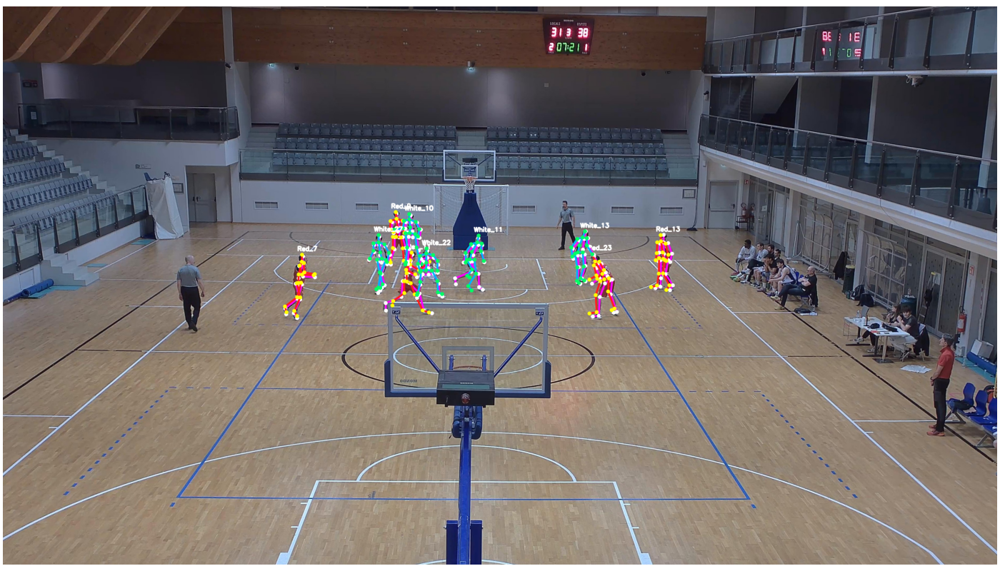

In [31]:
# Enable interactive Matplotlib backend for native zoom/pan
%matplotlib widget

BASE_DIR = Path.cwd()
TARGET_PLAYERS = ['Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9', 
                  'White_10', 'White_11', 'White_13', 'White_22', 'White_27']

def create_interactive_viewer(show_ba_default=False):
    '''
    Creates an independent instance of the interactive visualization tool.
    By encapsulating the setup in this function, each notebook cell gets its own
    separate figure and UI controls, preventing layout overlap and state corruption
    across multiple cell executions.

    Args:
        show_ba_default (bool): Determines if the Bundle Adjustment checkbox 
                                should be checked by default upon generation.
    '''
    # 1. MATPLOTLIB CANVAS SETUP
    
    # Disable automatic drawing to prevent an issue 
    plt.ioff()

    # Increased figure size and applied constrained layout for maximum image visibility
    fig, ax = plt.subplots(figsize=(14, 8), layout="constrained")

    #Re-enable interactive mode
    plt.ion()
    
    fig.canvas.header_visible = False  # Hide Jupyter header for a cleaner UI layout
    ax.axis('off')                     # Hide pixel axis ticks and borders

    # Create an empty image placeholder. 
    im_display = ax.imshow(np.zeros((1080, 1920, 3), dtype=np.uint8))

    # 2. MAIN UPDATE FUNCTION
    def update_reprojection_view(cam_id, target_frame, show_gt, show_reproj, show_ba):
        '''
        Reads the target image and overlays Ground Truth, Reprojection, and 
        Bundle Adjustment skeletons based on user checkbox selections.
        Allows to toggle visibility of each skeleton type independently.

        Args:
            cam_id (str): Camera ID to visualize.
            target_frame (int): Frame number to visualize.
            show_gt (bool): Whether to overlay Ground Truth skeletons.
            show_reproj (bool): Whether to overlay standard Reprojected skeletons.
            show_ba (bool): Whether to overlay Bundle Adjustment skeletons.

        Returns:
            None: Updates the local Matplotlib image canvas in place.
        '''
        cam_str = str(cam_id)
        
        # --- Image Loading ---
        # Attempt to load the image handling dynamic filenames (e.g., out3_01.jpg)
        frame_str = f"{target_frame:02d}"
        image_path = BASE_DIR / "rectified_images" / "hpe_rect_01" / f"out{cam_str}_{frame_str}.jpg"

        # Fallback if the image uses standard integer naming without leading zeros
        if not image_path.exists():
            image_path = BASE_DIR / "rectified_images" / "hpe_rect_01" / f"out{cam_str}_{target_frame}.jpg"

        # Read image using OpenCV (loaded in BGR format by default)
        img = cv2.imread(str(image_path))
        if img is None:
            print(f"Unable to load image: {image_path}")
            return

        # --- Data Extraction ---
        # Safely extract 2D points dictionaries for the current camera and frame
        camera_data = points_2d_dict.get(cam_str, {})
        frame_data = camera_data.get(target_frame, {})
        gt_frame_data = keypoints_2d_dict.get(target_frame, {})
        
        # Iterate through all target players to draw their respective skeletons
        for player in TARGET_PLAYERS:
            
            # --- A. Draw Ground Truth Skeleton ---
            if show_gt and player in gt_frame_data:
                # Handle dictionary keys that might be strings or integers
                gt_raw = gt_frame_data[player].get(cam_str) or gt_frame_data[player].get(int(cam_str))
                
                if gt_raw is not None:
                    gt_joints, gt_vis = [], []
                    # Ground truth data is assumed to be flattened (x, y, visibility)
                    for i in range(0, len(gt_raw), 3):
                        gt_joints.append((gt_raw[i], gt_raw[i+1]))
                        gt_vis.append(gt_raw[i+2])

                    # Draw bones between joints
                    for start_idx, end_idx in SKELETON_CONNECTIONS:
                        if start_idx < len(gt_joints) and end_idx < len(gt_joints):
                            # Only draw if both connected joints are visible
                            if gt_vis[start_idx] > 0 and gt_vis[end_idx] > 0:
                                p1 = (int(round(gt_joints[start_idx][0])), int(round(gt_joints[start_idx][1])))
                                p2 = (int(round(gt_joints[end_idx][0])), int(round(gt_joints[end_idx][1])))
                                cv2.line(img, p1, p2, (255, 0, 255), thickness=5, lineType=cv2.LINE_AA) # Magenta BGR

                    # Draw the actual joints as circles
                    for idx, pt in enumerate(gt_joints):
                        if gt_vis[idx] > 0:
                            center = (int(round(pt[0])), int(round(pt[1])))
                            cv2.circle(img, center, radius=7, color=(255, 255, 255), thickness=-1, lineType=cv2.LINE_AA)

            # --- B. Draw Standard Reprojected 3D Skeleton ---
            if show_reproj and player in frame_data:
                joints = frame_data[player]

                # Assign specific colors based on team (BGR format for OpenCV)
                color = (30, 30, 255) if player.startswith('Red') else (255, 180, 0)
                joint_color = (0, 255, 255) if player.startswith('Red') else (100, 255, 0)

                # Draw bones
                for start_idx, end_idx in SKELETON_CONNECTIONS:
                    if start_idx < len(joints) and end_idx < len(joints):
                        p1 = (int(round(joints[start_idx][0])), int(round(joints[start_idx][1])))
                        p2 = (int(round(joints[end_idx][0])), int(round(joints[end_idx][1])))
                        cv2.line(img, p1, p2, color, thickness=5, lineType=cv2.LINE_AA)

                label_drawn = False
                # Draw joints and player label
                for pt in joints:
                    center = (int(round(pt[0])), int(round(pt[1])))
                    cv2.circle(img, center, radius=7, color=joint_color, thickness=-1, lineType=cv2.LINE_AA)
                    
                    # Draw the label only once near the first joint processed
                    if not label_drawn:
                        cv2.putText(img, player, (center[0] - 18, center[1] - 15),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 3, cv2.LINE_AA)
                        label_drawn = True

            # --- C. Draw Bundle Adjustment (BA) Reprojected Skeleton ---
            # The 'in globals()' check strictly prevents NameErrors if the BA step hasn't been executed yet
            if show_ba and 'reprojected_points_BA' in globals():
                ba_frame_data = reprojected_points_BA.get(cam_str, {}).get(target_frame, {})
                
                if player in ba_frame_data:
                    ba_joints = ba_frame_data[player]

                    # Differentiate BA colors from standard reprojection
                    ba_color = (0, 165, 255) if player.startswith('Red') else (255, 0, 100)
                    ba_joint_color = (255, 255, 255)

                    # Draw bones
                    for start_idx, end_idx in SKELETON_CONNECTIONS:
                        if start_idx < len(ba_joints) and end_idx < len(ba_joints):
                            p1 = (int(round(ba_joints[start_idx][0])), int(round(ba_joints[start_idx][1])))
                            p2 = (int(round(ba_joints[end_idx][0])), int(round(ba_joints[end_idx][1])))
                            cv2.line(img, p1, p2, ba_color, thickness=5, lineType=cv2.LINE_AA)

                    label_drawn = False
                    # Draw joints and BA specific label
                    for pt in ba_joints:
                        center = (int(round(pt[0])), int(round(pt[1])))
                        cv2.circle(img, center, radius=7, color=ba_joint_color, thickness=-1, lineType=cv2.LINE_AA)
                        
                        # Avoid text overlap: only draw the BA label if the standard reprojection is hidden
                        if not label_drawn and not show_reproj: 
                            cv2.putText(img, f"{player} (BA)", (center[0] - 18, center[1] - 15),
                                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 3, cv2.LINE_AA)
                            label_drawn = True

        # --- Canvas Update Routine ---
        # OpenCV uses BGR natively, but Matplotlib expects RGB. We must convert it.
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Update image data directly to preserve current zoom/pan state
        im_display.set_data(img_rgb)
        
        # Force canvas update
        fig.canvas.draw_idle()


    # 3. INTERACTIVE CONTROLS SETUP
    # Sliders for Camera and Frame selection
    cam_slider = widgets.SelectionSlider(options=['1', '2', '3', '4', '5', '7'], value='1', description='Camera:', continuous_update=False)
    frame_slider = widgets.IntSlider(min=1, max=5, step=1, value=1, description='Frame:', continuous_update=False)

    # Checkboxes to toggle specific data overlays
    gt_checkbox = widgets.Checkbox(value=True, description='Show Ground Truth')
    reproj_checkbox = widgets.Checkbox(value=True, description='Show Reprojection')
    
    # Initialize the BA checkbox based on the function argument
    ba_checkbox = widgets.Checkbox(value=show_ba_default, description='Show BA Reprojection')

    # Bind the UI controls to the main update function
    interactive_controls = widgets.interactive_output(
        update_reprojection_view, 
        {
            'cam_id': cam_slider, 
            'target_frame': frame_slider,
            'show_gt': gt_checkbox,
            'show_reproj': reproj_checkbox,
            'show_ba': ba_checkbox
        }
    )

    # Print a static legend for the user
    print("\n--- Legend ---")
    print("Ground Truth: MAGENTA")
    print("Standard Reproj: RED (Red Team) / LIGHT BLUE (White Team)")
    print("Bundle Adj Reproj: ORANGE (Red Team) / PURPLE (White Team)")

    # Organize UI components into Vertical (VBox) and Horizontal (HBox) containers
    sliders_layout = widgets.VBox([cam_slider, frame_slider])
    checkboxes_layout = widgets.HBox([gt_checkbox, reproj_checkbox, ba_checkbox])
    controls_layout = widgets.VBox([sliders_layout, checkboxes_layout])

    # Display UI controls AND the locally scoped figure canvas
    display(controls_layout, interactive_controls, fig.canvas)


# Call the function to create an independent interactive viewer instance
create_interactive_viewer(show_ba_default=False)

These results give us an idea on how our implementation of the recunstruction is working, with some numbers and visualization. We can see that in some cases it works well, achieving good results, but it can be improved, up to now we just implemented a simple triangulation function and took the camera parameters given by the professors. 

Let's try to further improve our work by implementing a more sophisticated triangulation function or a Bundle Adjustment to refine the camera calibration.

# Bundle Adjustment 

We proceed to refine the camera intrinsic and extrinsic parameters by applying Bundle Adjustment. The comprehensive optimization procedure, objective functions, and parameter update steps are fully documented in `bundle_adjustment.ipynb`.

With the updated calibration metrics generated, we rerun the 3D triangulation and 2D reprojection workflows to quantify accuracy gains across the multi-camera setup.

In [32]:
BA_CALIB_DIR = os.path.abspath(os.path.join(SCRIPT_DIR, "camera_data_after_BA","camera_data"))


# Define available cameras in the setup
CAMS_ID = ["1", "2", "3", "4", "5", "7"]

P_dict_BA, K_dict_BA, dist_dict_BA = load_all_cams_params(CAMS_ID, BA_CALIB_DIR)

if not P_dict_BA:
    print("[CRITICAL ERROR] No calibrations loaded. Aborting.")
    exit()

print(f"Camera matrix P of the first camera: \n{P_dict_BA['1']}")
print(f"\n Intrinsic parameter matrix K of the first camera: \n{K_dict_BA['1']}")
print(f"\n Distorsion coefficients dist of the first camera: \n{dist_dict_BA['1']}")

Camera matrix P of the first camera: 
[[ 1.75267697e+03 -4.23733226e+03 -4.20276939e+02  4.60323107e+07]
 [ 2.61916682e+02 -1.02523969e+02 -4.33741101e+03  3.44935731e+07]
 [ 9.66479447e-01 -4.99015545e-02 -2.51847798e-01  2.56058529e+04]]

 Intrinsic parameter matrix K of the first camera: 
[[4.14227979e+03 0.00000000e+00 2.01122156e+03]
 [0.00000000e+00 4.13135205e+03 1.35062061e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

 Distorsion coefficients dist of the first camera: 
[[-0.34455085  0.20521682  0.00099386 -0.0027857  -0.12956857]]


## Triangulation Visualization

In this section we call the visualizzation functions to visualize the 3D skeletons as done before

### Sinlge Skeletons

In [33]:
interact(
    update_single_skeleton_plot, 
    target_frame=frame_slider, 
    target_player=player_dropdown,
    P_dict=fixed(P_dict_BA),
    K_dict=fixed(K_dict_BA),
    dist_dict=fixed(dist_dict_BA)
)

interactive(children=(IntSlider(value=1, continuous_update=False, description='Frame:', max=5, min=1), Dropdow…

<function __main__.update_single_skeleton_plot(target_frame, target_player, P_dict, K_dict, dist_dict)>

### All players in the field

In [34]:
interact(
    update_3d_court_plot, 
    target_frame=frame_slider_3d, 
    P_dict=fixed(P_dict_BA),      
    K_dict=fixed(K_dict_BA), 
    dist_dict=fixed(dist_dict_BA)
)

interactive(children=(IntSlider(value=1, continuous_update=False, description='Frame:', max=5, min=1), Output(…

<function __main__.update_3d_court_plot(target_frame, P_dict, K_dict, dist_dict)>

### Players Animation

In [35]:
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection='3d')

frames_sequence = list(range(1, 6)) * 5  # Repeat frames 1 to 5, five times for a total of 25 frames

anim = FuncAnimation(fig, update_3D_all_players, fargs=(P_dict_BA, K_dict_BA, dist_dict_BA), frames=frames_sequence, interval=150, repeat=False)

# Uncomment to save the animation as a MP4
#anim.save('animation_3d_post_BA.mp4', writer='ffmpeg', fps=7)

# Close the figure to prevent it from displaying twice in Jupyter Notebook
plt.close(fig)
HTML(anim.to_jshtml())

/tmp/ipykernel_1800/327847197.py:164: MatplotlibDeprecationWarning: The dist attribute was deprecated in Matplotlib 3.6 and will be removed two minor releases later.
  ax.dist = 7      # For older versions


## 2D Reprojection

As done previously, we proceed to reproject the reconstructed 3D points back into the 2D image plane.

In [36]:
skeleton3d_dict_BA = {}

# Reconstruct 3D skeletons for each frame and player using the Bundle Adjustment calibration parameters
for frame in TARGET_FRAMES:
    skeleton3d_dict_BA[frame] = {}
    for player in TARGET_PLAYERS:
        keypoints_2d_BA = extract_keypoints_single_frame(COCO_JSON_PATH, player, frame)
        skeleton3d = reconstruct_3d_skeleton(keypoints_2d_BA, P_dict_BA, K_dict_BA, dist_dict_BA, triangulation_function=SELECTED_TRIANGULATION_METHOD)
        skeleton3d_dict_BA[frame][player] = skeleton3d

# Reproject the 3D skeletons back to 2D for each camera using the Bundle Adjustment calibration parameters
points_2d_dict_BA = project_3d_to_2d(
    cams=['1', '2', '3', '4', '5', '7'],
    target_frames=TARGET_FRAMES,
    target_players=TARGET_PLAYERS,
    skeleton3d_dict=skeleton3d_dict_BA,
    P_dict=P_dict_BA
)

print(f"'points_2d_dict' has {len(points_2d_dict_BA)} cameras, {len(points_2d_dict_BA['5'])} different frames per camera, {len(points_2d_dict_BA['5'][1])} players per frame and {len(points_2d_dict_BA['5'][1]['Red_11'])} 2D coordinates per player")

'points_2d_dict' has 6 cameras, 5 different frames per camera, 10 players per frame and 18 2D coordinates per player


First I build the dictionaries that store 2d ground truth points and reprojected 3D points as done previously.

Structure of the dictionaries of the points:

- REPROJECTED: `points_2d_dict_BA[camera][frame][player]` returns `(18,2)`, thus 18 couples of x,y coordinates of the joints
- GROUND TRUTH: `keypoints_2d_dict_BA[frame][player][camera]` returns `54` (18*3 since we have x,y,v for each joint) elements

In [37]:
keypoints_2d_dict_BA = {}

for frame in TARGET_FRAMES:
    keypoints_2d_dict_BA[frame] = {}
    
    for player in TARGET_PLAYERS:
        # Extract the cam dictionary {'1': [54 elem], '2': [54 elem], ...}
        keypoints_2d_BA = extract_keypoints_single_frame(COCO_JSON_PATH, player, frame)
        
        rectified_cameras_dict_BA = {}
        
        # Cycle on the cams for that player
        for cam_id, kp_54 in keypoints_2d_BA.items():
            # Control for cam indexing
            K_BA = K_dict_BA.get(cam_id) if cam_id in K_dict_BA else K_dict_BA.get(int(cam_id))
            dist_BA = dist_dict_BA.get(cam_id) if cam_id in dist_dict_BA else dist_dict_BA.get(int(cam_id))
            
            rectified_kp_BA = rectify_skeleton(kp_54, K_BA, dist_BA)
            rectified_cameras_dict_BA[cam_id] = np.concatenate(rectified_kp_BA).tolist()
        
        # Save the rectified points in the dictionary
        keypoints_2d_dict_BA[frame][player] = rectified_cameras_dict_BA


# reprojected_points[camera][frame][player]
reprojected_points_BA = points_2d_dict_BA
# gt_points[frame][player][camera]
gt_points_BA = keypoints_2d_dict_BA

### 2D Projections Animation

The active camera view can be selected by updating the `CAM_ID` variable (e.g., `CAM_ID = '3'`).

In [38]:
CAM_ID = '5'
TARGET_FRAMES = list(range(1, 6))
BASE_DIR = Path.cwd()
TARGET_PLAYERS = ['Red_11', 'Red_13', 'Red_23', 'Red_7', 'Red_9', 'White_10', 'White_11', 'White_13', 'White_22', 'White_27']

# Call the function and display the output (in Jupyter Notebook / Colab)
animation_html = create_skeleton_animation(CAM_ID, TARGET_FRAMES, points_2d_dict_BA, TARGET_PLAYERS, BASE_DIR)
display(animation_html)

## Errors Computation

In this section, we re-compute the previously defined error metrics to evaluate whether performance has improved.

### Pixels Error

In [39]:
# Evaluate the pixel error metric across all cameras, frames, and players
df_px_BA = evaluate_metric(
    reprojected_points_BA, 
    gt_points_BA, 
    compute_skeleton_pixel_error, 
    metric_name="Error PX",
    available_frames=AVAILABLE_FRAMES
)

# Helper function to render evaluation tables for the pixel error metric
render_evaluation_tables(
    df=df_px_BA, 
    metric_col="Error PX", 
    value_format="{:.2f} px", 
    base_title="Reprojection Pixel Error (MPE)"
)

Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,10.50 px,22.36 px,50.45 px,13.93 px,30.05 px,29.07 px,26.06 px
Red_13,5.40 px,nan px,16.92 px,nan px,19.02 px,60.23 px,25.39 px
Red_23,5.23 px,nan px,10.81 px,nan px,9.04 px,40.01 px,16.27 px
Red_7,4.41 px,3.72 px,nan px,6.53 px,11.51 px,5.39 px,6.31 px
Red_9,5.81 px,nan px,23.70 px,12.60 px,25.42 px,47.17 px,22.94 px
White_10,8.78 px,nan px,18.89 px,12.87 px,31.50 px,19.37 px,18.28 px
White_11,20.51 px,nan px,22.47 px,28.68 px,37.89 px,32.42 px,28.39 px
White_13,5.12 px,nan px,13.98 px,12.96 px,15.63 px,33.00 px,16.14 px
White_22,5.86 px,nan px,17.43 px,15.54 px,23.14 px,37.89 px,19.97 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,8.36 px,17.09 px,12.59 px,19.28 px,28.93 px,25.16 px,18.57 px
Red_13,4.33 px,nan px,14.81 px,nan px,17.38 px,55.82 px,23.09 px
Red_23,5.91 px,nan px,12.68 px,nan px,9.56 px,43.31 px,17.87 px
Red_7,4.98 px,5.24 px,nan px,8.59 px,14.01 px,6.15 px,7.79 px
Red_9,8.56 px,nan px,21.28 px,15.84 px,28.47 px,51.35 px,25.10 px
White_10,5.95 px,nan px,19.82 px,15.43 px,32.95 px,19.61 px,18.75 px
White_11,7.93 px,nan px,16.94 px,13.46 px,27.42 px,18.57 px,16.86 px
White_13,5.79 px,nan px,12.04 px,14.72 px,12.69 px,30.91 px,15.23 px
White_22,6.11 px,nan px,17.63 px,11.58 px,18.53 px,37.25 px,18.22 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,4.93 px,nan px,14.48 px,8.69 px,19.18 px,25.20 px,14.49 px
Red_13,5.96 px,nan px,15.14 px,nan px,17.31 px,60.09 px,24.62 px
Red_23,4.77 px,nan px,15.16 px,nan px,9.44 px,52.74 px,20.53 px
Red_7,3.94 px,7.20 px,nan px,10.89 px,20.60 px,6.77 px,9.88 px
Red_9,7.76 px,nan px,22.50 px,12.19 px,30.38 px,52.68 px,25.10 px
White_10,7.08 px,nan px,14.33 px,14.51 px,21.80 px,19.41 px,15.43 px
White_11,6.10 px,nan px,15.45 px,11.85 px,22.64 px,21.52 px,15.51 px
White_13,5.99 px,nan px,11.34 px,13.50 px,16.61 px,30.35 px,15.56 px
White_22,11.55 px,nan px,13.91 px,25.85 px,29.68 px,30.54 px,22.31 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,17.38 px,nan px,18.64 px,29.17 px,26.76 px,35.08 px,25.41 px
Red_13,6.42 px,nan px,16.07 px,nan px,17.86 px,69.13 px,27.37 px
Red_23,6.36 px,nan px,19.55 px,nan px,23.58 px,50.84 px,25.08 px
Red_7,5.74 px,8.86 px,nan px,11.18 px,19.46 px,7.43 px,10.53 px
Red_9,8.96 px,nan px,22.30 px,14.98 px,36.83 px,48.90 px,26.39 px
White_10,6.22 px,nan px,12.69 px,14.98 px,23.75 px,21.84 px,15.89 px
White_11,7.28 px,nan px,14.11 px,12.36 px,17.98 px,25.27 px,15.40 px
White_13,5.25 px,nan px,11.66 px,13.19 px,15.99 px,28.65 px,14.95 px
White_22,9.05 px,nan px,20.67 px,14.15 px,26.13 px,49.65 px,23.93 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,28.50 px,nan px,36.73 px,42.49 px,52.61 px,33.08 px,38.68 px
Red_13,4.17 px,nan px,15.30 px,nan px,19.21 px,66.14 px,26.20 px
Red_23,5.35 px,nan px,17.29 px,nan px,18.32 px,49.85 px,22.70 px
Red_7,4.35 px,8.10 px,nan px,8.49 px,19.94 px,9.52 px,10.08 px
Red_9,11.34 px,nan px,15.50 px,10.87 px,37.85 px,30.55 px,21.22 px
White_10,7.50 px,nan px,12.31 px,13.86 px,21.36 px,18.89 px,14.78 px
White_11,4.96 px,nan px,12.35 px,9.06 px,13.54 px,28.69 px,13.72 px
White_13,14.00 px,nan px,52.58 px,26.63 px,42.27 px,85.25 px,44.14 px
White_22,6.94 px,nan px,16.20 px,11.52 px,19.35 px,40.45 px,18.89 px


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,13.93 px,19.73 px,26.58 px,22.71 px,31.51 px,29.52 px,24.47 px
Red_13,5.25 px,nan px,15.65 px,nan px,18.15 px,62.28 px,25.33 px
Red_23,5.52 px,nan px,15.10 px,nan px,13.99 px,47.35 px,20.49 px
Red_7,4.69 px,6.62 px,nan px,9.14 px,17.10 px,7.05 px,8.92 px
Red_9,8.49 px,nan px,21.06 px,13.30 px,31.79 px,46.13 px,24.15 px
White_10,7.10 px,nan px,15.61 px,14.33 px,26.27 px,19.83 px,16.63 px
White_11,9.36 px,nan px,16.26 px,15.08 px,23.89 px,25.30 px,17.98 px
White_13,7.23 px,nan px,20.32 px,16.20 px,20.64 px,41.63 px,21.20 px
White_22,7.90 px,nan px,17.17 px,15.73 px,23.37 px,39.16 px,20.66 px


### OKS Error

In [40]:
# Call the evaluation function to compute the OKS metric across all cameras, frames, and players
df_oks_BA = evaluate_metric(
    reprojected_points_BA, 
    gt_points_BA, 
    calculate_oks_single_skeleton, 
    metric_name="OKS",
    available_frames=AVAILABLE_FRAMES
)

# Call the helper function to render the evaluation tables for the OKS metric
render_evaluation_tables(
    df=df_oks_BA, 
    metric_col="OKS", 
    value_format="{:.4f}", 
    base_title="Object Keypoint Similarity (OKS)"
)

Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.7650,0.6948,0.3776,0.8601,0.3963,0.3182,0.5687
Red_13,0.7804,nan,0.5038,nan,0.5773,0.3100,0.5429
Red_23,0.8799,nan,0.7931,nan,0.8253,0.2769,0.6938
Red_7,0.9112,0.9648,nan,0.9164,0.7204,0.8608,0.8747
Red_9,0.7652,nan,0.7591,0.7891,0.5787,0.2595,0.6303
White_10,0.6683,nan,0.8011,0.8542,0.5654,0.5101,0.6798
White_11,0.5710,nan,0.6382,0.6679,0.2916,0.3425,0.5022
White_13,0.8352,nan,0.7337,0.8456,0.7220,0.4911,0.7255
White_22,0.7926,nan,0.7259,0.7093,0.4911,0.2851,0.6008


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.7844,0.5870,0.7344,0.6896,0.3925,0.3068,0.5824
Red_13,0.8673,nan,0.6326,nan,0.7060,0.4313,0.6593
Red_23,0.8915,nan,0.7714,nan,0.8166,0.2902,0.6924
Red_7,0.9011,0.9269,nan,0.8640,0.6802,0.8145,0.8373
Red_9,0.6633,nan,0.7924,0.7537,0.5380,0.1534,0.5802
White_10,0.8351,nan,0.8069,0.8203,0.5563,0.5488,0.7134
White_11,0.6974,nan,0.7277,0.8237,0.5269,0.4924,0.6536
White_13,0.7915,nan,0.7982,0.7939,0.8129,0.5270,0.7447
White_22,0.8143,nan,0.7247,0.8359,0.5616,0.3246,0.6522


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.9109,nan,0.7201,0.9238,0.4837,0.2856,0.6648
Red_13,0.7771,nan,0.5853,nan,0.6311,0.3149,0.5771
Red_23,0.8932,nan,0.6858,nan,0.8200,0.2089,0.6520
Red_7,0.9107,0.8754,nan,0.8155,0.4854,0.7239,0.7622
Red_9,0.7225,nan,0.7647,0.8398,0.5608,0.1707,0.6117
White_10,0.7828,nan,0.8779,0.8403,0.7584,0.6012,0.7721
White_11,0.8779,nan,0.7600,0.9208,0.5469,0.5015,0.7215
White_13,0.7640,nan,0.8073,0.8581,0.6815,0.4949,0.7212
White_22,0.5285,nan,0.7224,0.4917,0.2591,0.2413,0.4486


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.5624,nan,0.6730,0.6082,0.3008,0.2180,0.4725
Red_13,0.7085,nan,0.6590,nan,0.6403,0.2555,0.5658
Red_23,0.7977,nan,0.5207,nan,0.4025,0.2234,0.4861
Red_7,0.8579,0.8628,nan,0.7988,0.4839,0.7426,0.7492
Red_9,0.6837,nan,0.7976,0.8016,0.5125,0.2437,0.6078
White_10,0.8260,nan,0.9187,0.8627,0.7521,0.5336,0.7786
White_11,0.7032,nan,0.7344,0.8204,0.5648,0.4079,0.6461
White_13,0.7421,nan,0.8037,0.8396,0.6723,0.5217,0.7159
White_22,0.6858,nan,0.6654,0.7912,0.4028,0.3349,0.5760


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.2075,nan,0.3442,0.3991,0.1419,0.2627,0.2711
Red_13,0.8269,nan,0.6668,nan,0.6347,0.2932,0.6054
Red_23,0.8381,nan,0.6719,nan,0.6108,0.3106,0.6079
Red_7,0.8866,0.8648,nan,0.8218,0.3712,0.6866,0.7262
Red_9,0.5455,nan,0.8647,0.8776,0.4367,0.3086,0.6066
White_10,0.7843,nan,0.9325,0.8653,0.7728,0.5530,0.7816
White_11,0.8732,nan,0.8323,0.9108,0.7953,0.4579,0.7739
White_13,0.2945,nan,0.1836,0.6035,0.2876,0.0630,0.2864
White_22,0.7534,nan,0.7039,0.8412,0.4980,0.3460,0.6285


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,0.6461,0.6409,0.5699,0.6961,0.3430,0.2783,0.5166
Red_13,0.7920,nan,0.6095,nan,0.6379,0.3210,0.5901
Red_23,0.8601,nan,0.6886,nan,0.6950,0.2620,0.6264
Red_7,0.8935,0.8989,nan,0.8433,0.5482,0.7657,0.7899
Red_9,0.6760,nan,0.7957,0.8124,0.5253,0.2272,0.6073
White_10,0.7793,nan,0.8674,0.8486,0.6810,0.5493,0.7451
White_11,0.7445,nan,0.7385,0.8287,0.5451,0.4404,0.6595
White_13,0.6855,nan,0.6653,0.7881,0.6352,0.4195,0.6387
White_22,0.7149,nan,0.7085,0.7339,0.4425,0.3064,0.5812


### CM Error

In [41]:
# Compute CM errors
df_cm_BA = evaluate_metric(
    reprojected_points_BA, 
    gt_points_BA, 
    metric_func=lambda gt, reproj, c_id, f_id, p_name: compute_err_cm(
        gt,     # 2D Ground truth points
        reproj, # 3D reprojected points
        points_3d=skeleton3d_dict_BA[f_id][p_name],  # skeleton in frame f_id of player p_name
        K_matrix=K_dict_BA.get(c_id, K_dict_BA.get(int(c_id))),  # K matrix for cam c_id
        P_matrix=P_dict_BA.get(c_id, P_dict_BA.get(int(c_id)))   # P matrix for cam c_id
    ),
    metric_name="Error (cm)",
    available_frames=AVAILABLE_FRAMES,
    pass_context=True  
)

# Call the helper function to render the evaluation tables for the reprojection error in centimeters
render_evaluation_tables(
    df=df_cm_BA, 
    metric_col="Error (cm)", 
    value_format="{:.2f} cm", 
    base_title="Reprojection Error in CM"
)

Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,7.55 cm,11.27 cm,18.98 cm,5.48 cm,15.17 cm,18.86 cm,12.89 cm
Red_13,4.39 cm,nan cm,7.65 cm,nan cm,7.63 cm,19.12 cm,9.70 cm
Red_23,3.76 cm,nan cm,4.98 cm,nan cm,4.49 cm,16.91 cm,7.54 cm
Red_7,3.07 cm,1.95 cm,nan cm,2.86 cm,6.06 cm,4.11 cm,3.61 cm
Red_9,5.24 cm,nan cm,6.48 cm,3.87 cm,8.00 cm,31.97 cm,11.11 cm
White_10,7.85 cm,nan cm,5.33 cm,3.89 cm,10.09 cm,12.63 cm,7.96 cm
White_11,16.47 cm,nan cm,8.24 cm,9.44 cm,15.97 cm,18.67 cm,13.76 cm
White_13,4.28 cm,nan cm,5.60 cm,3.44 cm,5.92 cm,13.89 cm,6.63 cm
White_22,4.47 cm,nan cm,6.32 cm,5.64 cm,10.60 cm,23.96 cm,10.20 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,6.05 cm,8.50 cm,4.83 cm,7.40 cm,14.46 cm,15.65 cm,9.48 cm
Red_13,3.52 cm,nan cm,6.73 cm,nan cm,6.96 cm,17.33 cm,8.64 cm
Red_23,4.26 cm,nan cm,5.85 cm,nan cm,4.73 cm,18.04 cm,8.22 cm
Red_7,3.45 cm,2.73 cm,nan cm,3.77 cm,7.44 cm,4.67 cm,4.41 cm
Red_9,7.72 cm,nan cm,5.81 cm,4.84 cm,8.91 cm,34.57 cm,12.37 cm
White_10,5.33 cm,nan cm,5.57 cm,4.64 cm,10.43 cm,12.69 cm,7.73 cm
White_11,6.29 cm,nan cm,6.40 cm,4.35 cm,11.66 cm,10.03 cm,7.74 cm
White_13,4.86 cm,nan cm,4.80 cm,3.83 cm,4.74 cm,13.01 cm,6.25 cm
White_22,4.68 cm,nan cm,6.47 cm,4.12 cm,8.42 cm,23.00 cm,9.34 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,3.61 cm,nan cm,5.57 cm,3.23 cm,9.31 cm,15.24 cm,7.39 cm
Red_13,4.85 cm,nan cm,6.89 cm,nan cm,6.92 cm,18.36 cm,9.26 cm
Red_23,3.45 cm,nan cm,7.01 cm,nan cm,4.68 cm,21.49 cm,9.16 cm
Red_7,2.71 cm,3.70 cm,nan cm,4.76 cm,11.03 cm,5.02 cm,5.45 cm
Red_9,7.00 cm,nan cm,6.11 cm,3.74 cm,9.48 cm,35.59 cm,12.38 cm
White_10,6.36 cm,nan cm,4.03 cm,4.32 cm,6.87 cm,12.50 cm,6.82 cm
White_11,4.80 cm,nan cm,6.00 cm,3.78 cm,9.72 cm,11.10 cm,7.08 cm
White_13,5.06 cm,nan cm,4.48 cm,3.53 cm,6.15 cm,12.79 cm,6.40 cm
White_22,8.89 cm,nan cm,5.14 cm,9.00 cm,13.30 cm,18.10 cm,10.89 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,13.02 cm,nan cm,7.17 cm,10.62 cm,12.82 cm,21.03 cm,12.93 cm
Red_13,5.23 cm,nan cm,7.34 cm,nan cm,7.10 cm,20.88 cm,10.14 cm
Red_23,4.65 cm,nan cm,9.03 cm,nan cm,11.41 cm,20.34 cm,11.36 cm
Red_7,3.94 cm,4.48 cm,nan cm,4.82 cm,10.51 cm,5.34 cm,5.82 cm
Red_9,8.07 cm,nan cm,6.03 cm,4.61 cm,11.53 cm,33.23 cm,12.70 cm
White_10,5.58 cm,nan cm,3.58 cm,4.47 cm,7.51 cm,14.05 cm,7.04 cm
White_11,5.68 cm,nan cm,5.66 cm,3.91 cm,7.89 cm,12.56 cm,7.14 cm
White_13,4.44 cm,nan cm,4.61 cm,3.43 cm,5.90 cm,12.07 cm,6.09 cm
White_22,7.02 cm,nan cm,7.72 cm,4.87 cm,11.64 cm,29.15 cm,12.08 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,21.52 cm,nan cm,13.87 cm,15.25 cm,24.59 cm,19.79 cm,19.00 cm
Red_13,3.41 cm,nan cm,6.97 cm,nan cm,7.58 cm,19.84 cm,9.45 cm
Red_23,3.94 cm,nan cm,7.99 cm,nan cm,8.76 cm,19.69 cm,10.10 cm
Red_7,2.98 cm,4.04 cm,nan cm,3.62 cm,10.79 cm,6.64 cm,5.61 cm
Red_9,10.23 cm,nan cm,4.12 cm,3.38 cm,11.84 cm,21.08 cm,10.13 cm
White_10,6.72 cm,nan cm,3.48 cm,4.17 cm,6.82 cm,12.21 cm,6.68 cm
White_11,3.86 cm,nan cm,5.04 cm,2.84 cm,5.97 cm,13.86 cm,6.31 cm
White_13,11.89 cm,nan cm,20.80 cm,6.87 cm,15.51 cm,36.08 cm,18.23 cm
White_22,5.43 cm,nan cm,6.06 cm,3.88 cm,8.51 cm,23.39 cm,9.45 cm


Camera,Cam 1,Cam 2,Cam 3,Cam 4,Cam 5,Cam 7,PLAYER MEAN
Player,,,,,,,
Red_11,10.35 cm,9.89 cm,10.09 cm,8.39 cm,15.27 cm,18.11 cm,12.25 cm
Red_13,4.28 cm,nan cm,7.12 cm,nan cm,7.24 cm,19.11 cm,9.44 cm
Red_23,4.01 cm,nan cm,6.97 cm,nan cm,6.81 cm,19.29 cm,9.27 cm
Red_7,3.23 cm,3.38 cm,nan cm,3.97 cm,9.16 cm,5.16 cm,4.98 cm
Red_9,7.65 cm,nan cm,5.71 cm,4.09 cm,9.95 cm,31.29 cm,11.74 cm
White_10,6.37 cm,nan cm,4.40 cm,4.30 cm,8.34 cm,12.82 cm,7.24 cm
White_11,7.42 cm,nan cm,6.27 cm,4.87 cm,10.24 cm,13.25 cm,8.41 cm
White_13,6.11 cm,nan cm,8.06 cm,4.22 cm,7.65 cm,17.57 cm,8.72 cm
White_22,6.10 cm,nan cm,6.34 cm,5.50 cm,10.49 cm,23.52 cm,10.39 cm


As can be seen from the quantitative results, the overall error metrics have significantly improved, clearly demonstrating the effectiveness of the BA procedure. Taking the CM error as a primary example, the initial deviation was recorded at 12.27 cm. Following the optimization process, this error was successfully reduced to just 8.72 cm. This substantial decrease of approximately 29% not only highlights the robustness of the BA approach in refining the system's parameters, but also confirms that the procedure is crucial for achieving a much more accurate, reliable, and consistent final model.

### Skeletons comparison pre- and post- BA

Finally we plot together the 2D skeletons to better see the BA effectiveness.

By utilizing the interactive widget below, we can more effectively visualize the impact of the optimization by directly comparing the "before" and "after" states of the projections. 

Prior to optimization, the most problematic viewpoints, and those contributing the most to the overall systemic error, were Cameras 3 and 5. By selecting these specific cameras within the widget, one can clearly observe the geometric improvements: the Post-BA projected skeletons are significantly closer to the Ground Truth (GT) annotations compared to the Pre-BA estimates.

This visual evidence perfectly corroborates the quantitative reductions in error discussed previously. It confirms that the Bundle Adjustment procedure successfully mitigates the initial calibration inaccuracies, pulling the reconstructed projections back into proper spatial alignment. Ultimately, this ensures a highly reliable and geometrically consistent multi-camera setup, capable of producing robust 3D reconstructions.

The remaining residual errors are likely due to the imperfect quality of the 2D ground truth annotations. Manual keypoint labeling in the dataset suffers from human error, coarse placement, and spatial inconsistencies across frames. Since the optimizer relies on these annotations as a reference, any flaw in the 2D labels directly caps the maximum achievable projection accuracy.


--- Legend ---
Ground Truth: MAGENTA
Standard Reproj: RED (Red Team) / LIGHT BLUE (White Team)
Bundle Adj Reproj: ORANGE (Red Team) / PURPLE (White Team)

--- Legend ---
Ground Truth: MAGENTA
Standard Reproj: RED (Red Team) / LIGHT BLUE (White Team)
Bundle Adj Reproj: ORANGE (Red Team) / PURPLE (White Team)


Output()

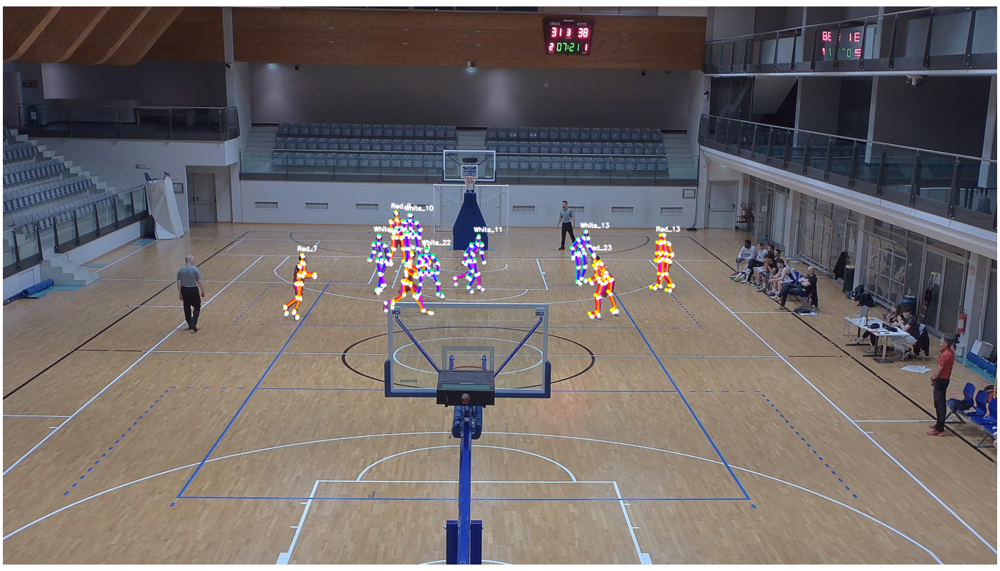

In [42]:
# Print legend for skeleton color coding
print("\n--- Legend ---")
print("Ground Truth: MAGENTA")
print("Standard Reproj: RED (Red Team) / LIGHT BLUE (White Team)")
print("Bundle Adj Reproj: ORANGE (Red Team) / PURPLE (White Team)")

# Call the function to create an independent interactive viewer instance for Bundle Adjustment results
create_interactive_viewer(show_ba_default=True)